# DGM Homework 2 | Real NVP and GANs

## Round 1 | Setup and affine coupling

Use the project's `.venv` interpreter as the notebook kernel. Run the cells below in order. This round works with a few synthetic points and checks the math before we train on Two Moons.

The `required` tag marks the setup and affine coupling code used by the assignment experiments. The `non-required` tag marks explanations and optional sanity checks.

For the implementation requirements, see Question 1 of [Homework 2](DGM_HW2.pdf). For the derivation, see sections 3.2–3.3 of [Density Estimation Using Real NVP](papers/density-estimation-using-real-NVP.pdf).

In [5]:
import random

import numpy as np
import torch
from torch import nn
from torch.func import functional_call

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {DEVICE} | seed: {SEED}")

PyTorch 2.15.0+cu134 | device: cuda | seed: 42


### What the mask does

A mask value of 1 fixes a coordinate and lets it condition both networks. A value of 0 marks a coordinate to transform. With $x_m=m\odot x$, the scale network produces $s(x_m)$ and the shift network produces $t(x_m)$. Both outputs are masked to zero on the fixed coordinates.

$$
y = m\odot x + (1-m)\odot \bigl(x\odot e^{s(x_m)} + t(x_m)\bigr).
$$

The inverse can recompute the same scale and shift because $m\odot y=x_m$. The Jacobian has a triangular block structure when the fixed coordinates come first. The transformed coordinates contribute $e^{s_i}$ on the diagonal, so the forward log-determinant is the sum of $s_i$ over the transformed coordinates **for each sample**. The inverse has the opposite log-determinant.

The homework uses two separate MLPs with three hidden layers of width 128. On the transformed coordinates, we use $s=a_s\odot\tanh(\tilde{s})$ and $t=a_t\odot\tilde{t}+b_t$. Initializing $a_s,a_t,b_t$ to zero starts the layer at the identity while the MLP weights use PyTorch's default initialization.

In [6]:
def make_conditioner(num_features, hidden_width):
    return nn.Sequential(
        nn.Linear(num_features, hidden_width),
        nn.ReLU(),
        nn.Linear(hidden_width, hidden_width),
        nn.ReLU(),
        nn.Linear(hidden_width, hidden_width),
        nn.ReLU(),
        nn.Linear(hidden_width, num_features),
    )


class AffineCoupling(nn.Module):
    """Transform the unmasked coordinates of inputs shaped (batch, features)."""

    def __init__(self, mask, hidden_width=128):
        super().__init__()
        mask = torch.as_tensor(mask, dtype=torch.float32).clone()
        if mask.ndim != 1 or mask.numel() == 0 or not ((mask == 0) | (mask == 1)).all():
            raise ValueError("mask must be a nonempty vector of zeros and ones")
        self.register_buffer("mask", mask)

        num_features = mask.numel()
        self.s_net = make_conditioner(num_features, hidden_width)
        self.t_net = make_conditioner(num_features, hidden_width)
        self.a_s = nn.Parameter(torch.zeros(num_features))
        self.a_t = nn.Parameter(torch.zeros(num_features))
        self.b_t = nn.Parameter(torch.zeros(num_features))

    def forward(self, inputs, *, inverse=False):
        fixed = self.mask * inputs
        changed = 1 - self.mask
        scale = self.a_s * self.s_net(fixed).tanh() * changed
        shift = (self.a_t * self.t_net(fixed) + self.b_t) * changed
        log_det = scale.sum(dim=-1)

        if inverse:
            outputs = (inputs - shift) * (-scale).exp()
            return fixed + changed * outputs, -log_det

        outputs = inputs * scale.exp() + shift
        return fixed + changed * outputs, log_det

## Round 2 | Real NVP on Two Moons

Run the Round 1 setup and affine coupling cells before this section. For this experiment, we generate 20,000 training points and 5,000 independent evaluation points with noise 0.06. Both splits use the training mean and standard deviation.

The required cells define the 2D flow, run an eight-layer baseline, and compare depth and mask choices. **Run the two cells marked TRAINING yourself.** Run the baseline and its evaluation before the ablations.

In [16]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

MOONS_TRAIN_SIZE = 20_000
MOONS_EVAL_SIZE = 5_000
MOONS_NOISE = 0.06
MOONS_BASELINE_DEPTH = 8
MOONS_DEPTHS = (1, 2, 4, 8, 16)
MOONS_BATCH_SIZE = 512
MOONS_STEPS = 3_000
MOONS_LEARNING_RATE = 1e-3
MOONS_GRAD_CLIP = 10.0
MOONS_OUTPUT = Path("results") / "two_moons"

train_raw, _ = make_moons(
    n_samples=MOONS_TRAIN_SIZE, noise=MOONS_NOISE, random_state=SEED
)
eval_raw, _ = make_moons(
    n_samples=MOONS_EVAL_SIZE, noise=MOONS_NOISE, random_state=SEED + 1
)
train_mean = train_raw.mean(axis=0)
train_std = train_raw.std(axis=0)

moons_train = torch.as_tensor(
    (train_raw - train_mean) / train_std, dtype=torch.float32, device=DEVICE
)
moons_eval = torch.as_tensor(
    (eval_raw - train_mean) / train_std, dtype=torch.float32, device=DEVICE
)
print(f"Two Moons on {DEVICE} | train: {len(moons_train):,} | evaluation: {len(moons_eval):,}")

Two Moons on cuda | train: 20,000 | evaluation: 5,000


### From a coupling layer to a density

The forward pass maps data to latent space and adds the layer log-determinants. The inverse applies the layers in reverse order. For the standard-normal prior, the data log-density is

$$
\log p_X(x) = -\tfrac12\bigl(\lVert z\rVert^2 + 2\log(2\pi)\bigr)
             + \sum_{k=1}^K \log|\det J_k|.
$$

The loss is the negative mean of this value over the batch, in **nats per sample**. To generate points, draw from the latent prior and map those draws back to data space.

In [17]:
class TwoMoonsFlow(nn.Module):
    """A stack of 2D couplings with a standard-normal latent prior."""

    def __init__(self, depth, *, alternating=True):
        super().__init__()
        if depth < 1:
            raise ValueError("depth must be at least one")
        masks = ([1, 0], [0, 1])
        self.layers = nn.ModuleList(
            AffineCoupling(masks[index % 2] if alternating else masks[0])
            for index in range(depth)
        )

    def forward(self, x):
        total_log_det = x.new_zeros(x.shape[0])
        for layer in self.layers:
            x, log_det = layer(x)
            total_log_det = total_log_det + log_det
        return x, total_log_det

    def inverse(self, z):
        for layer in reversed(self.layers):
            z, _ = layer(z, inverse=True)
        return z

    def log_prob(self, x):
        z, log_det = self(x)
        prior_log_prob = -0.5 * (z.square().sum(dim=-1) + 2 * math.log(2 * math.pi))
        return prior_log_prob + log_det

    @torch.inference_mode()
    def sample(self, count, *, generator):
        mask = self.layers[0].mask
        z = torch.randn(count, 2, generator=generator, device=mask.device, dtype=mask.dtype)
        return self.inverse(z)

In [18]:
def fit_moons_flow(depth, *, alternating=True):
    """Train a fresh flow with a reproducible initialization and batch sequence."""
    torch.manual_seed(SEED)
    model = TwoMoonsFlow(depth, alternating=alternating).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=MOONS_LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MOONS_STEPS)
    batch_generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    losses = moons_train.new_empty(MOONS_STEPS)
    mask_name = "alternating" if alternating else "fixed"
    model.train()

    for step in range(1, MOONS_STEPS + 1):
        indices = torch.randperm(
            len(moons_train), device=DEVICE, generator=batch_generator
        )[:MOONS_BATCH_SIZE]
        batch = moons_train[indices]
        optimizer.zero_grad(set_to_none=True)
        loss = -model.log_prob(batch).mean()
        loss.backward()
        if MOONS_GRAD_CLIP is not None:
            nn.utils.clip_grad_norm_(model.parameters(), MOONS_GRAD_CLIP)
        optimizer.step()
        scheduler.step()
        losses[step - 1] = loss.detach()

        if step == 1 or step % 500 == 0 or step == MOONS_STEPS:
            loss_value = loss.item()
            if not math.isfinite(loss_value):
                raise FloatingPointError(f"Non-finite loss at step {step} for depth {depth}")
            print(f"K={depth:>2}, {mask_name:>11} | step {step:>4}/{MOONS_STEPS} | NLL {loss_value:.4f}")

    model.eval()
    with torch.inference_mode():
        eval_nll = -model.log_prob(moons_eval).mean().item()
    if not math.isfinite(eval_nll):
        raise FloatingPointError(f"Non-finite evaluation NLL for depth {depth}")
    return model, losses.cpu().numpy(), eval_nll

In [ ]:
baseline_flow, baseline_losses, baseline_nll = fit_moons_flow(MOONS_BASELINE_DEPTH)
print(f"Baseline evaluation NLL: {baseline_nll:.4f} nats/sample")

K= 8, alternating | step    1/3000 | NLL 2.8242
K= 8, alternating | step  500/3000 | NLL 1.4862
K= 8, alternating | step 1000/3000 | NLL 1.3705
K= 8, alternating | step 1500/3000 | NLL 1.3473
K= 8, alternating | step 2000/3000 | NLL 1.3396
K= 8, alternating | step 2500/3000 | NLL 1.3695
K= 8, alternating | step 3000/3000 | NLL 1.2957
Baseline evaluation NLL: 1.3493 nats/sample


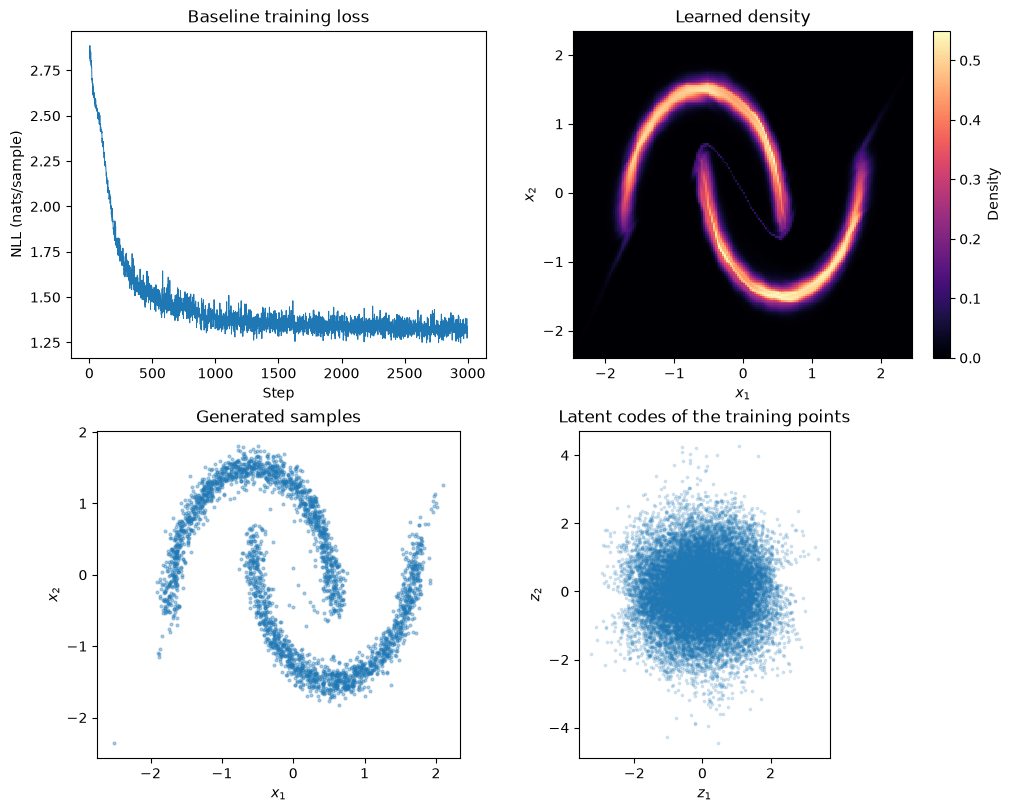

In [20]:
@torch.inference_mode()
def moons_density(model, grid, shape):
    log_density = torch.cat([model.log_prob(batch) for batch in grid.split(4096)])
    return log_density.exp().reshape(shape).cpu().numpy()


moons_data = moons_train.cpu().numpy()
x1_values = np.linspace(moons_data[:, 0].min() - 0.5, moons_data[:, 0].max() + 0.5, 180)
x2_values = np.linspace(moons_data[:, 1].min() - 0.5, moons_data[:, 1].max() + 0.5, 180)
grid_x1, grid_x2 = np.meshgrid(x1_values, x2_values)
moons_grid = torch.as_tensor(
    np.column_stack((grid_x1.ravel(), grid_x2.ravel())), dtype=moons_train.dtype, device=DEVICE
)
baseline_density = moons_density(baseline_flow, moons_grid, grid_x1.shape)
sample_generator = torch.Generator(device=DEVICE).manual_seed(SEED + 2)
generated = baseline_flow.sample(3_000, generator=sample_generator).cpu().numpy()
with torch.inference_mode():
    train_latents, _ = baseline_flow(moons_train)
    train_latents = train_latents.cpu().numpy()

fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
axes[0, 0].plot(np.arange(1, len(baseline_losses) + 1), baseline_losses, lw=0.7)
axes[0, 0].set(title="Baseline training loss", xlabel="Step", ylabel="NLL (nats/sample)")
density_image = axes[0, 1].pcolormesh(grid_x1, grid_x2, baseline_density, cmap="magma", shading="auto")
fig.colorbar(density_image, ax=axes[0, 1], label="Density")
axes[0, 1].set(title="Learned density", xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
axes[1, 0].scatter(generated[:, 0], generated[:, 1], s=4, alpha=0.35)
axes[1, 0].set(title="Generated samples", xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
axes[1, 1].scatter(train_latents[:, 0], train_latents[:, 1], s=3, alpha=0.16)
axes[1, 1].set(title="Latent codes of the training points", xlabel="$z_1$", ylabel="$z_2$", aspect="equal")

MOONS_OUTPUT.mkdir(parents=True, exist_ok=True)
fig.savefig(MOONS_OUTPUT / "baseline.png", dpi=180)
plt.show()

### Depth and mask comparisons

The depth sweep reuses the eight-layer baseline and trains fresh alternating-mask flows at the other depths. The fixed-mask run keeps eight layers and uses [1, 0] in every layer. All runs use the same data, batch sequence, and learning-rate schedule.

Compare the held-out NLL across depths and look for where extra layers stop helping. In the fixed-mask model the first coordinate never changes, so its generated marginal stays the standard-normal prior. Look for that restriction in the learned density and compare both mask settings on a shared color scale.

In [ ]:
depth_nll = {MOONS_BASELINE_DEPTH: baseline_nll}
for depth in MOONS_DEPTHS:
    if depth != MOONS_BASELINE_DEPTH:
        _, _, depth_nll[depth] = fit_moons_flow(depth)

fixed_mask_flow, _, fixed_mask_nll = fit_moons_flow(MOONS_BASELINE_DEPTH, alternating=False)

K= 1, alternating | step    1/3000 | NLL 2.8242
K= 1, alternating | step  500/3000 | NLL 2.3142
K= 1, alternating | step 1000/3000 | NLL 2.2431
K= 1, alternating | step 1500/3000 | NLL 2.1561
K= 1, alternating | step 2000/3000 | NLL 2.1809
K= 1, alternating | step 2500/3000 | NLL 2.1259
K= 1, alternating | step 3000/3000 | NLL 2.1109
K= 2, alternating | step    1/3000 | NLL 2.8242
K= 2, alternating | step  500/3000 | NLL 2.0946
K= 2, alternating | step 1000/3000 | NLL 2.0993
K= 2, alternating | step 1500/3000 | NLL 2.0341
K= 2, alternating | step 2000/3000 | NLL 2.0832
K= 2, alternating | step 2500/3000 | NLL 2.0236
K= 2, alternating | step 3000/3000 | NLL 1.9878
K= 4, alternating | step    1/3000 | NLL 2.8242
K= 4, alternating | step  500/3000 | NLL 1.6951
K= 4, alternating | step 1000/3000 | NLL 1.5542
K= 4, alternating | step 1500/3000 | NLL 1.6114
K= 4, alternating | step 2000/3000 | NLL 1.5205
K= 4, alternating | step 2500/3000 | NLL 1.5105
K= 4, alternating | step 3000/3000 | NLL

Alternating masks, K= 1: 2.1266 nats/sample
Alternating masks, K= 2: 2.0383 nats/sample
Alternating masks, K= 4: 1.5333 nats/sample
Alternating masks, K= 8: 1.3493 nats/sample
Alternating masks, K=16: 1.3594 nats/sample
Fixed mask, K= 8: 2.1165 nats/sample


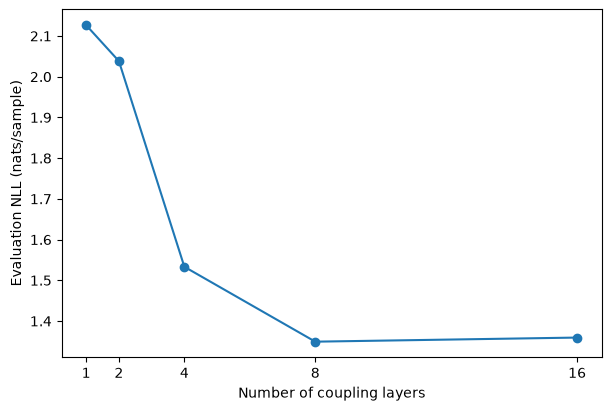

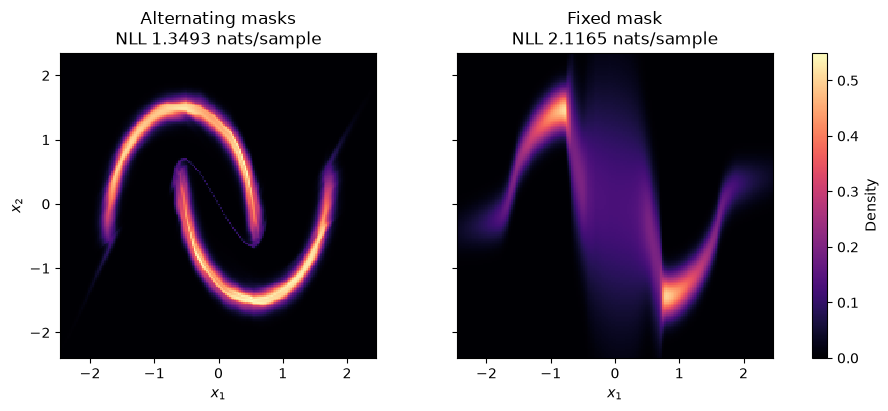

Saved figures and metrics in results\two_moons


In [22]:
for depth in MOONS_DEPTHS:
    print(f"Alternating masks, K={depth:>2}: {depth_nll[depth]:.4f} nats/sample")
print(f"Fixed mask, K={MOONS_BASELINE_DEPTH:>2}: {fixed_mask_nll:.4f} nats/sample")

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.plot(MOONS_DEPTHS, [depth_nll[depth] for depth in MOONS_DEPTHS], marker="o")
ax.set(xticks=MOONS_DEPTHS, xlabel="Number of coupling layers", ylabel="Evaluation NLL (nats/sample)")
fig.savefig(MOONS_OUTPUT / "depth_comparison.png", dpi=180)
plt.show()

fixed_density = moons_density(fixed_mask_flow, moons_grid, grid_x1.shape)
shared_max = max(baseline_density.max(), fixed_density.max())
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True, layout="constrained")
for axis, density, title, nll in zip(
    axes,
    (baseline_density, fixed_density),
    ("Alternating masks", "Fixed mask"),
    (baseline_nll, fixed_mask_nll),
):
    comparison_image = axis.pcolormesh(
        grid_x1, grid_x2, density, cmap="magma", vmin=0, vmax=shared_max, shading="auto"
    )
    axis.set(title=f"{title}\nNLL {nll:.4f} nats/sample", xlabel="$x_1$", aspect="equal")
axes[0].set_ylabel("$x_2$")
fig.colorbar(comparison_image, ax=axes, label="Density")
fig.savefig(MOONS_OUTPUT / "mask_comparison.png", dpi=180)
plt.show()

moons_metrics = {
    "train_seed": SEED,
    "eval_seed": SEED + 1,
    "train_size": MOONS_TRAIN_SIZE,
    "eval_size": MOONS_EVAL_SIZE,
    "noise": MOONS_NOISE,
    "batch_size": MOONS_BATCH_SIZE,
    "steps": MOONS_STEPS,
    "learning_rate": MOONS_LEARNING_RATE,
    "gradient_clip": MOONS_GRAD_CLIP,
    "baseline_depth": MOONS_BASELINE_DEPTH,
    "alternating_mask_nll_nats_per_sample": depth_nll,
    "fixed_mask_nll_nats_per_sample": fixed_mask_nll,
}
(MOONS_OUTPUT / "metrics.json").write_text(
    json.dumps(moons_metrics, indent=2, sort_keys=True) + "\n", encoding="utf-8"
)
print(f"Saved figures and metrics in {MOONS_OUTPUT}")

## Round 3 | MNIST data and reversible layers

Run the Round 1 setup cell first. This section prepares the MNIST splits and builds the transformations we will use in the image flow. It contains no training cells.

The first data run caches the standard MNIST files under `data/MNIST`. We split the official training set into 55,000 training and 5,000 validation images and keep the official 10,000-image test set for final evaluation. The tensors stay as raw 8-bit pixels until preprocessing.

The shape and normalization rules follow Question 1 of [Homework 2](DGM_HW2.pdf). Sections 3.6–3.7 of [Density Estimation Using Real NVP](papers/density-estimation-using-real-NVP.pdf) give the motivation for squeeze and flow normalization.

In [23]:
from pathlib import Path

from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision.datasets import MNIST

MNIST_ROOT = Path("data")
MNIST_BATCH_SIZE = 128
MNIST_ALPHA = 0.05

raw_mnist_train = MNIST(MNIST_ROOT, train=True, download=True)
raw_mnist_test = MNIST(MNIST_ROOT, train=False, download=True)

mnist_train_set, mnist_val_set = random_split(
    TensorDataset(raw_mnist_train.data.unsqueeze(1), raw_mnist_train.targets),
    [55_000, 5_000],
    generator=torch.Generator().manual_seed(SEED),
)
mnist_test_set = TensorDataset(raw_mnist_test.data.unsqueeze(1), raw_mnist_test.targets)


def make_mnist_loaders(*, batch_size=MNIST_BATCH_SIZE, seed=SEED):
    """Create loaders with a fresh, reproducible training shuffle."""
    options = {
        "batch_size": batch_size,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
    }
    train_loader = DataLoader(
        mnist_train_set, shuffle=True, generator=torch.Generator().manual_seed(seed), **options
    )
    val_loader = DataLoader(mnist_val_set, shuffle=False, **options)
    test_loader = DataLoader(mnist_test_set, shuffle=False, **options)
    return train_loader, val_loader, test_loader


print(f"MNIST | train: {len(mnist_train_set):,} | validation: {len(mnist_val_set):,} | test: {len(mnist_test_set):,}")

MNIST | train: 55,000 | validation: 5,000 | test: 10,000


### From pixel bins to logits

A pixel with integer value $k$ represents a bin. Adding uniform noise inside that bin gives $x=(k+u)/256$ with $u\sim\mathcal U[0,1)$. Dequantization is stochastic. The invertible part starts at $x$.

Before taking logits, map $x$ to $p=\alpha+(1-2\alpha)x$ using $\alpha=0.05$. This keeps the logit finite at both ends. Sum the log-Jacobian across all pixels to get one value per image.

$$
y=\log p-\log(1-p),
\qquad
\log\left|\frac{dy}{dx}\right|=\log(1-2\alpha)-\log p-\log(1-p).
$$

The inverse returns continuous pixel values. For display, we will clamp the inverse output to the unit interval after sampling.

In [24]:
import math


def dequantize_mnist(pixels, *, generator=None):
    """Convert raw uint8 pixel bins to continuous values in [0, 1)."""
    bins = pixels.to(dtype=torch.float32)
    noise = torch.rand(bins.shape, device=bins.device, dtype=bins.dtype, generator=generator)
    unit = (bins + noise) / 256.0
    # Adding noise to bin 255 can round up to 1 in float32.
    return unit.clamp_max(1.0 - torch.finfo(unit.dtype).eps / 2)


def mnist_to_logits(unit, *, alpha=MNIST_ALPHA):
    """Return logits and the log-Jacobian sum for each image."""
    p = alpha + (1.0 - 2.0 * alpha) * unit
    log_p = p.log()
    log_one_minus_p = torch.log1p(-p)
    logits = log_p - log_one_minus_p
    pixel_log_det = math.log1p(-2.0 * alpha) - log_p - log_one_minus_p
    return logits, pixel_log_det.flatten(start_dim=1).sum(dim=1)


def mnist_from_logits(logits, *, alpha=MNIST_ALPHA):
    """Invert the logit transform before any clipping for display."""
    return (logits.sigmoid() - alpha) / (1.0 - 2.0 * alpha)

### Squeeze and unsqueeze

Squeeze moves each spatial $2\times2$ block into four channels. An image batch with shape $(B,C,H,W)$ becomes $(B,4C,H/2,W/2)$. This only reorders entries, so the absolute Jacobian determinant is one and its log is zero. The assignment asks us to show that unsqueezing recovers the input exactly.

In [25]:
def squeeze2d(x):
    return F.pixel_unshuffle(x, downscale_factor=2)


def unsqueeze2d(z):
    return F.pixel_shuffle(z, upscale_factor=2)


example_image, _ = mnist_train_set[0]
example_batch = example_image.unsqueeze(0)
squeezed_image = squeeze2d(example_batch)
recovered_image = unsqueeze2d(squeezed_image)
assert torch.equal(recovered_image, example_batch)
print(f"{tuple(example_batch.shape)} -> {tuple(squeezed_image.shape)} -> {tuple(recovered_image.shape)}")
print("Squeeze followed by unsqueeze recovers every pixel exactly.")

(1, 1, 28, 28) -> (1, 4, 14, 14) -> (1, 1, 28, 28)
Squeeze followed by unsqueeze recovers every pixel exactly.


### Batch normalization as a flow layer

This layer applies one affine transform per channel. It uses current minibatch statistics on the training forward pass, with population variance over the batch and spatial dimensions. The first batch initializes the running statistics. Later batches update them with momentum 0.05.

In evaluation and in the inverse, the layer uses the stored running statistics. The affine transform of a forward pass made with current batch statistics can differ from the one used by the inverse. Check the round trip in evaluation mode, where both directions use the same values.

With channel log-scale $\ell_c=\gamma_c-\tfrac12\log(\sigma_c^2+\varepsilon)$, the forward log-determinant is $HW\sum_c\ell_c$ per image. This flow layer will sit after each coupling. The conditioning networks will have their own per-image normalization in Round 4.

In [26]:
class FlowBatchNorm2d(nn.Module):
    """Batch normalization with an explicit inverse and log-determinant."""

    def __init__(self, channels, *, eps=1e-5, momentum=0.05):
        super().__init__()
        self.eps = eps
        self.momentum = momentum
        self.gamma = nn.Parameter(torch.zeros(channels))
        self.beta = nn.Parameter(torch.zeros(channels))
        self.register_buffer("running_mean", torch.zeros(channels))
        self.register_buffer("running_var", torch.ones(channels))
        self.register_buffer("num_batches_tracked", torch.zeros((), dtype=torch.long))

    def forward(self, x, *, inverse=False):
        if self.training and not inverse:
            var, mean = torch.var_mean(x, dim=(0, 2, 3), correction=0)
            with torch.no_grad():
                # A tensor weight avoids a CPU branch on a CUDA scalar.
                first_batch = (self.num_batches_tracked == 0).to(self.running_mean.dtype)
                weight = self.momentum + (1.0 - self.momentum) * first_batch
                self.running_mean.lerp_(mean.detach().to(self.running_mean.dtype), weight)
                self.running_var.lerp_(var.detach().to(self.running_var.dtype), weight)
                self.num_batches_tracked.add_(1)
        else:
            mean, var = self.running_mean, self.running_var

        log_scale = self.gamma - 0.5 * (var + self.eps).log()
        log_det = (x.shape[-2] * x.shape[-1] * log_scale.sum()).expand(x.shape[0])
        scale = log_scale[None, :, None, None]
        center = mean[None, :, None, None]
        shift = self.beta[None, :, None, None]

        if inverse:
            return (x - shift) * (-scale).exp() + center, -log_det
        return (x - center) * scale.exp() + shift, log_det

### Optional numerical checks

Use a few pixels to compare the logit Jacobian to autograd. Then pass two synthetic batches through a temporary normalization layer to check the running statistics and evaluation inverse.

In [27]:
unit_example = torch.tensor([[[[0.0, 0.23], [0.71, 0.99]]]], device=DEVICE, dtype=torch.float64)
logits, logit_log_det = mnist_to_logits(unit_example)
torch.testing.assert_close(mnist_from_logits(logits), unit_example, rtol=0, atol=1e-12)
jacobian = torch.autograd.functional.jacobian(
    lambda values: mnist_to_logits(values.reshape_as(unit_example))[0].flatten(),
    unit_example.flatten(),
)
torch.testing.assert_close(logit_log_det[0], torch.linalg.slogdet(jacobian).logabsdet)
print("Logit round trip and log-determinant check passed.")

norm = FlowBatchNorm2d(2).to(device=DEVICE, dtype=torch.float64)
first = torch.arange(32, device=DEVICE, dtype=torch.float64).reshape(2, 2, 2, 4) / 10
second = 1.5 * first + 2.0
stats_dims = (0, 2, 3)
first_var, first_mean = torch.var_mean(first, dim=stats_dims, correction=0)
second_var, second_mean = torch.var_mean(second, dim=stats_dims, correction=0)
with torch.no_grad():
    norm(first)
    torch.testing.assert_close(norm.running_mean, first_mean, rtol=0, atol=0)
    torch.testing.assert_close(norm.running_var, first_var, rtol=0, atol=0)
    norm(second)
    torch.testing.assert_close(norm.running_mean, 0.95 * first_mean + 0.05 * second_mean)
    torch.testing.assert_close(norm.running_var, 0.95 * first_var + 0.05 * second_var)

    norm.eval()
    transformed, forward_log_det = norm(first)
    recovered, inverse_log_det = norm(transformed, inverse=True)
    torch.testing.assert_close(recovered, first, rtol=0, atol=1e-12)
    torch.testing.assert_close(forward_log_det, -inverse_log_det, rtol=0, atol=0)
    assert norm.num_batches_tracked.item() == 2
print("Flow BatchNorm first-batch, moving-average and evaluation inverse checks passed.")

Logit round trip and log-determinant check passed.
Flow BatchNorm first-batch, moving-average and evaluation inverse checks passed.


## Round 4 | Multi-scale Real NVP on MNIST

Run the setup and required Round 3 cells first. This round assembles the flow defined in Question 1 of [Homework 2](DGM_HW2.pdf). The two factor-out operations follow the idea in [Real NVP, section 3.6](papers/density-estimation-using-real-NVP.pdf).

| Stage | Transforms in the forward direction | Latent chunk |
| --- | --- | --- |
| Scale 1 | 3 checkerboard couplings, squeeze to `4 x 14 x 14`, 3 channel couplings, split | `z1` is `2 x 14 x 14` (392) |
| Scale 2 | 3 checkerboard couplings, squeeze to `8 x 7 x 7`, 3 channel couplings, split | `z2` is `4 x 7 x 7` (196) |
| Final | 4 checkerboard couplings at `4 x 7 x 7` | `z3` is `4 x 7 x 7` (196) |

Each stack alternates between a mask and its complement. A `1` keeps that coordinate fixed and supplies it to the two separate conditioners $s$ and $t$. Each conditioner uses 64 hidden channels, two residual blocks and per-image instance normalization. The affine coupling starts as the identity because its three learned coefficients start at zero. A flow batch normalization follows each coupling.

In [28]:
class ConditionerResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.norm1 = nn.InstanceNorm2d(channels, affine=False)
        self.norm2 = nn.InstanceNorm2d(channels, affine=False)

    def forward(self, x):
        h = F.relu(self.norm1(self.conv1(x)))
        return F.relu(self.norm2(self.conv2(h)) + x)


def make_image_conditioner(channels, hidden_channels, residual_blocks):
    return nn.Sequential(
        nn.Conv2d(channels, hidden_channels, 3, padding=1, bias=False),
        *(ConditionerResidualBlock(hidden_channels) for _ in range(residual_blocks)),
        nn.Conv2d(hidden_channels, channels, 3, padding=1, bias=False),
    )


class ImageAffineCoupling(nn.Module):
    def __init__(self, image_shape, mask, *, hidden_channels, residual_blocks):
        super().__init__()
        self.register_buffer('mask', mask)
        channels = image_shape[0]
        self.s_net = make_image_conditioner(channels, hidden_channels, residual_blocks)
        self.t_net = make_image_conditioner(channels, hidden_channels, residual_blocks)
        self.a_s = nn.Parameter(torch.zeros(image_shape))
        self.a_t = nn.Parameter(torch.zeros(image_shape))
        self.b_t = nn.Parameter(torch.zeros(image_shape))

    def forward(self, x, *, inverse=False):
        fixed = x * self.mask
        changed = 1.0 - self.mask
        scale = self.a_s * self.s_net(fixed).tanh() * changed
        shift = (self.a_t * self.t_net(fixed) + self.b_t) * changed
        log_det = scale.flatten(start_dim=1).sum(dim=1)
        if inverse:
            return fixed + changed * (x - shift) * (-scale).exp(), -log_det
        return fixed + changed * (x * scale.exp() + shift), log_det


class ImageCouplingStack(nn.Module):
    def __init__(self, image_shape, count, mask_kind, *, hidden_channels, residual_blocks):
        super().__init__()
        channels, height, width = image_shape
        if mask_kind == 'checkerboard':
            parity = (torch.arange(height)[:, None] + torch.arange(width)[None, :]) % 2
            mask = (parity == 0)[None, :, :].float()
        elif mask_kind == 'channel':
            mask = (torch.arange(channels) < channels // 2)[:, None, None].float()
        else:
            raise ValueError(f'Unknown image mask: {mask_kind}')

        self.layers = nn.ModuleList()
        for index in range(count):
            self.layers.append(ImageAffineCoupling(
                image_shape, mask if index % 2 == 0 else 1.0 - mask,
                hidden_channels=hidden_channels, residual_blocks=residual_blocks,
            ))
            self.layers.append(FlowBatchNorm2d(channels))

    def forward(self, x, *, inverse=False):
        total_log_det = x.new_zeros(x.shape[0])
        layers = reversed(self.layers) if inverse else self.layers
        for layer in layers:
            x, log_det = layer(x, inverse=inverse)
            total_log_det = total_log_det + log_det
        return x, total_log_det

### Factor-out, likelihood and BPD

Each scale sends its first half of channels to the next scale and sets aside its second half. The inverse starts from `z3` and reinserts `z2` and `z1` before undoing their channel couplings and squeezes. Use `model.eval()` for a round trip so both directions use the same running statistics in flow batch normalization.

The model maps logits to `z`. For likelihood on continuous pixels `x`, `log_prob` includes the logit Jacobian in addition to the flow log-determinant and standard-normal log density. `bits_per_dim` returns one value per image using $8 - \log p_X(x)/(784 \log 2)$. The `8` accounts for the width of a pixel bin. Dequantize raw `uint8` batches before calling either method.

In [29]:
class MNISTRealNVP(nn.Module):
    latent_shapes = ((2, 14, 14), (4, 7, 7), (4, 7, 7))
    latent_sizes = tuple(map(math.prod, latent_shapes))
    num_pixels = sum(latent_sizes)

    def __init__(self, *, hidden_channels=64, residual_blocks=2):
        super().__init__()
        options = dict(hidden_channels=hidden_channels, residual_blocks=residual_blocks)
        self.checkerboard_stacks = nn.ModuleList([
            ImageCouplingStack((1, 28, 28), 3, 'checkerboard', **options),
            ImageCouplingStack((2, 14, 14), 3, 'checkerboard', **options),
        ])
        self.channel_stacks = nn.ModuleList([
            ImageCouplingStack((4, 14, 14), 3, 'channel', **options),
            ImageCouplingStack((8, 7, 7), 3, 'channel', **options),
        ])
        self.final_stack = ImageCouplingStack((4, 7, 7), 4, 'checkerboard', **options)

    def forward(self, logits):
        """Map image logits to a flat latent vector and return the flow log-determinant."""
        x = logits
        total_log_det = x.new_zeros(x.shape[0])
        chunks = []
        for checkerboard, channel in zip(self.checkerboard_stacks, self.channel_stacks):
            x, checkerboard_log_det = checkerboard(x)
            x, channel_log_det = channel(squeeze2d(x))
            x, factored = x.chunk(2, dim=1)
            chunks.append(factored.flatten(start_dim=1))
            total_log_det = total_log_det + checkerboard_log_det + channel_log_det
        x, final_log_det = self.final_stack(x)
        chunks.append(x.flatten(start_dim=1))
        return torch.cat(chunks, dim=1), total_log_det + final_log_det

    def inverse(self, z):
        """Recover image logits and return the inverse flow log-determinant."""
        z1, z2, z3 = (chunk.unflatten(1, shape) for chunk, shape in zip(
            z.split(self.latent_sizes, dim=1), self.latent_shapes,
        ))
        x, total_log_det = self.final_stack(z3, inverse=True)
        for checkerboard, channel, factored in zip(
            reversed(self.checkerboard_stacks), reversed(self.channel_stacks), (z2, z1),
        ):
            x, channel_log_det = channel(torch.cat((x, factored), dim=1), inverse=True)
            x, checkerboard_log_det = checkerboard(unsqueeze2d(x), inverse=True)
            total_log_det = total_log_det + channel_log_det + checkerboard_log_det
        return x, total_log_det

    def log_prob(self, unit_pixels):
        logits, logit_log_det = mnist_to_logits(unit_pixels)
        z, flow_log_det = self(logits)
        prior_log_prob = -0.5 * (z.square() + math.log(2 * math.pi)).sum(dim=1)
        return prior_log_prob + flow_log_det + logit_log_det

    def bits_per_dim(self, unit_pixels):
        return 8.0 - self.log_prob(unit_pixels) / (self.num_pixels * math.log(2.0))

### Check a forward and inverse pass

This optional check uses two training images, prints the latent sizes and parameter count, and verifies the image and log-determinant round trips. It runs the full reference model in evaluation mode.

In [30]:
@torch.inference_mode()
def check_mnist_flow():
    with torch.random.fork_rng(devices=[]):
        torch.random.default_generator.manual_seed(SEED)
        model = MNISTRealNVP().to(DEVICE).eval()
    pixels = torch.stack([mnist_train_set[i][0] for i in range(2)]).to(DEVICE)
    generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    unit = dequantize_mnist(pixels, generator=generator)
    logits, _ = mnist_to_logits(unit)
    z, forward_log_det = model(logits)
    recovered, inverse_log_det = model.inverse(z)
    bpd = model.bits_per_dim(unit)

    assert z.shape == (2, 784) and bpd.shape == (2,)
    assert torch.isfinite(z).all() and torch.isfinite(bpd).all()
    torch.testing.assert_close(recovered, logits, rtol=0, atol=2e-5)
    torch.testing.assert_close(mnist_from_logits(recovered), unit, rtol=0, atol=2e-6)
    torch.testing.assert_close(forward_log_det, -inverse_log_det, rtol=0, atol=2e-5)
    parameters = sum(parameter.numel() for parameter in model.parameters())
    print(f'Latent chunks {model.latent_sizes} | parameters {parameters:,} | device {DEVICE}')
    print('Pixel and log-determinant round trips passed. BPD is finite.')


check_mnist_flow()

Latent chunks (392, 196, 196) | parameters 4,882,778 | device cuda
Pixel and log-determinant round trips passed. BPD is finite.


### Optional training benchmark | Run manually

This cell performs short optimizer runs on a fresh model and reports measured step time, PyTorch CUDA peak memory and an estimate for 10 epochs. The estimate includes loader time, transfers, dequantization, training, and validation cost. The benchmark times evaluation on batches drawn from the training split so we can reserve the validation split for checkpoint selection. Checkpoint I/O and generating figures are outside the estimate.

Start with the reference settings (`128` images, `64` hidden channels, `2` residual blocks). If CUDA runs out of memory, restart the kernel and rerun setup and the required cells from Rounds 3 and 4. Then try a batch size of `64`. The benchmark discards its model when it finishes.

In [31]:
# TRAINING BENCHMARK | Run this cell manually after reviewing the model.
from time import perf_counter


def benchmark_mnist_realnvp(*, batch_size=MNIST_BATCH_SIZE, hidden_channels=64, residual_blocks=2):
    train_loader, val_loader, _ = make_mnist_loaders(batch_size=batch_size)
    batches = iter(train_loader)
    with torch.random.fork_rng(devices=[]):
        torch.random.default_generator.manual_seed(SEED)
        model = MNISTRealNVP(hidden_channels=hidden_channels, residual_blocks=residual_blocks).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
    generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    on_cuda = DEVICE.type == 'cuda'

    def batch_loss():
        pixels, _ = next(batches)
        unit = dequantize_mnist(pixels.to(DEVICE, non_blocking=on_cuda), generator=generator)
        return model.bits_per_dim(unit).mean()

    def train_step():
        optimizer.zero_grad(set_to_none=True)
        loss = batch_loss()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0, error_if_nonfinite=True)
        optimizer.step()

    def seconds_per_step(step, *, warmup, repeats):
        for _ in range(warmup):
            step()
        if on_cuda:
            torch.cuda.synchronize(DEVICE)
        start = perf_counter()
        for _ in range(repeats):
            step()
        if on_cuda:
            torch.cuda.synchronize(DEVICE)
        return (perf_counter() - start) / repeats

    print(f'Benchmarking {DEVICE} | batch {batch_size} | width {hidden_channels} | residual blocks {residual_blocks}')
    if on_cuda:
        torch.cuda.synchronize(DEVICE)
        torch.cuda.reset_peak_memory_stats(DEVICE)
    model.train()
    train_seconds = seconds_per_step(train_step, warmup=3, repeats=12)
    optimizer.zero_grad(set_to_none=True)
    model.eval()
    with torch.inference_mode():
        eval_seconds = seconds_per_step(batch_loss, warmup=2, repeats=6)

    epoch_seconds = train_seconds * len(train_loader) + eval_seconds * len(val_loader)
    print(f'Train {train_seconds:.3f} s/batch | evaluation {eval_seconds:.3f} s/batch')
    print(f'Estimated {epoch_seconds / 60:.1f} min/epoch | {10 * epoch_seconds / 3600:.2f} h for 10 epochs')
    if on_cuda:
        allocated = torch.cuda.max_memory_allocated(DEVICE) / 2**30
        reserved = torch.cuda.max_memory_reserved(DEVICE) / 2**30
        print(f'PyTorch CUDA peak in this kernel {allocated:.2f} GiB allocated | {reserved:.2f} GiB reserved')


benchmark_mnist_realnvp()

Benchmarking cuda | batch 128 | width 64 | residual blocks 2
Train 0.212 s/batch | evaluation 0.077 s/batch
Estimated 1.6 min/epoch | 0.26 h for 10 epochs
PyTorch CUDA peak in this kernel 2.27 GiB allocated | 2.42 GiB reserved


## Round 5 | MNIST training and evaluation

The saved CUDA benchmark measured 0.212 s per training batch and 0.077 s per evaluation batch, with 2.42 GiB peak reserved memory. We keep the reference model (64 hidden channels, two residual blocks, batch size 128). The benchmark projects about 16 minutes for the 10-epoch run and about 10 minutes for the two 3-epoch ablation runs combined. Checkpoint writes and figures add time.

Run the two setup cells below, then run **Training 1 of 3** manually. After it finishes, run the two evaluation cells. You can then run **Training 2 of 3** and **Training 3 of 3** and plot their comparison. Each run saves its own checkpoint with the model from the epoch with the lowest validation BPD. All outputs go under `results/mnist_realnvp/`.

In [32]:
import json
from tempfile import NamedTemporaryFile
from time import perf_counter

import matplotlib.pyplot as plt
from torchvision.utils import make_grid

MNIST_RESULTS = Path('results/mnist_realnvp')
MNIST_REFERENCE_EPOCHS = 10
MNIST_ABLATION_EPOCHS = 3
MNIST_PEAK_LR = 5e-4
MNIST_LOW_LR = 5e-5
MNIST_WARMUP_STEPS = 500
MNIST_FINAL_LR_FRACTION = 0.02
MNIST_MAX_GRAD_NORM = 10.0
MNIST_VAL_NOISE_SEED = SEED + 1
MNIST_TEST_NOISE_SEED = SEED + 2


def mnist_learning_rate(step, total_steps, peak_lr):
    """Return the learning rate for a one-based batch step."""
    if step <= MNIST_WARMUP_STEPS:
        return peak_lr * step / MNIST_WARMUP_STEPS
    progress = (step - MNIST_WARMUP_STEPS) / (total_steps - MNIST_WARMUP_STEPS)
    cosine = 0.5 * (1.0 + math.cos(math.pi * progress))
    return peak_lr * (MNIST_FINAL_LR_FRACTION + (1.0 - MNIST_FINAL_LR_FRACTION) * cosine)


@torch.inference_mode()
def evaluate_mnist_bpd(model, loader, *, seed):
    model.eval()
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    total = torch.zeros((), device=DEVICE, dtype=torch.float64)
    count = 0
    for pixels, _ in loader:
        unit = dequantize_mnist(pixels.to(DEVICE, non_blocking=DEVICE.type == 'cuda'), generator=generator)
        total += model.bits_per_dim(unit).sum(dtype=torch.float64)
        count += len(pixels)
    bpd = total.item() / count
    if not math.isfinite(bpd):
        raise FloatingPointError('Evaluation produced a nonfinite BPD.')
    return bpd


def save_mnist_run(run_name, record):
    path = MNIST_RESULTS / run_name / 'checkpoint.pt'
    path.parent.mkdir(parents=True, exist_ok=True)
    with NamedTemporaryFile(dir=path.parent, suffix='.tmp', delete=False) as handle:
        pending = Path(handle.name)
    try:
        torch.save(record, pending)
        pending.replace(path)
    finally:
        pending.unlink(missing_ok=True)


def read_mnist_run(run_name):
    path = MNIST_RESULTS / run_name / 'checkpoint.pt'
    if not path.is_file():
        raise FileNotFoundError(f'Run the training cell for {run_name!r} first. Missing {path}.')
    record = torch.load(path, map_location='cpu', weights_only=True)
    if len(record['history']) != record['config']['epochs']:
        raise RuntimeError(f'{run_name!r} ended before the last epoch. Run its training cell to completion.')
    return record

In [33]:
def fit_mnist_flow(run_name, *, epochs, peak_lr, batch_size=MNIST_BATCH_SIZE,
                   hidden_channels=64, residual_blocks=2):
    train_loader, val_loader, _ = make_mnist_loaders(batch_size=batch_size)
    with torch.random.fork_rng(devices=[]):
        torch.random.default_generator.manual_seed(SEED)
        model = MNISTRealNVP(hidden_channels=hidden_channels, residual_blocks=residual_blocks).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=peak_lr)
    generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    total_steps = epochs * len(train_loader)
    bn_buffers = [buffer for layer in model.modules() if isinstance(layer, FlowBatchNorm2d)
                  for buffer in layer.buffers(recurse=False)]
    record = {
        'config': {
            'epochs': epochs, 'peak_lr': peak_lr, 'batch_size': batch_size,
            'hidden_channels': hidden_channels, 'residual_blocks': residual_blocks,
            'couplings': 16, 'trainable_parameters': sum(p.numel() for p in model.parameters()),
            'optimizer': 'Adam', 'warmup_steps': MNIST_WARMUP_STEPS,
            'final_lr_fraction': MNIST_FINAL_LR_FRACTION, 'max_grad_norm': MNIST_MAX_GRAD_NORM,
            'seed': SEED, 'validation_noise_seed': MNIST_VAL_NOISE_SEED,
        },
        'history': [],
        'best_val_bpd': math.inf,
    }

    step = 0
    for epoch in range(1, epochs + 1):
        started = perf_counter()
        model.train()
        train_sum = torch.zeros((), device=DEVICE, dtype=torch.float64)
        seen, skipped = 0, 0
        for pixels, _ in train_loader:
            step += 1
            lr = mnist_learning_rate(step, total_steps, peak_lr)
            for group in optimizer.param_groups:
                group['lr'] = lr

            optimizer.zero_grad(set_to_none=True)
            unit = dequantize_mnist(pixels.to(DEVICE, non_blocking=DEVICE.type == 'cuda'), generator=generator)
            # The training forward updates moving statistics before we can check its gradients.
            saved_buffers = [buffer.clone() for buffer in bn_buffers]
            bpd = model.bits_per_dim(unit)
            loss = bpd.mean()
            loss.backward()
            grad_norm = nn.utils.clip_grad_norm_(model.parameters(), MNIST_MAX_GRAD_NORM)
            if not (torch.isfinite(loss.detach()) & torch.isfinite(grad_norm)).item():
                for buffer, saved in zip(bn_buffers, saved_buffers):
                    buffer.copy_(saved)
                skipped += 1
                continue

            optimizer.step()
            train_sum += bpd.detach().sum(dtype=torch.float64)
            seen += len(pixels)

        if seen == 0:
            raise FloatingPointError(f'{run_name}: all updates in epoch {epoch} were skipped.')
        train_bpd = train_sum.item() / seen
        val_bpd = evaluate_mnist_bpd(model, val_loader, seed=MNIST_VAL_NOISE_SEED)
        if val_bpd < record['best_val_bpd']:
            record['best_epoch'] = epoch
            record['best_val_bpd'] = val_bpd
            record['model_state'] = {name: tensor.detach().to(device='cpu', copy=True)
                                     for name, tensor in model.state_dict().items()}
        elapsed = perf_counter() - started
        record['history'].append({
            'epoch': epoch, 'train_bpd': train_bpd, 'val_bpd': val_bpd,
            'last_lr': lr, 'skipped_steps': skipped, 'seconds': elapsed,
        })
        save_mnist_run(run_name, record)
        print(f'{run_name} | epoch {epoch:02d}/{epochs} | train {train_bpd:.4f} BPD | '
              f'val {val_bpd:.4f} BPD | skipped {skipped} | {elapsed:.1f} s', flush=True)

    print(f"Best validation BPD {record['best_val_bpd']:.4f} at epoch {record['best_epoch']}.")

In [34]:
# TRAINING 1 OF 3 | Run this cell manually to fit the 10-epoch reference model.
fit_mnist_flow('reference', epochs=MNIST_REFERENCE_EPOCHS, peak_lr=MNIST_PEAK_LR)

reference | epoch 01/10 | train 4.7496 BPD | val 2.9982 BPD | skipped 0 | 97.7 s
reference | epoch 02/10 | train 2.3829 BPD | val 2.0304 BPD | skipped 0 | 99.6 s
reference | epoch 03/10 | train 1.8482 BPD | val 1.7381 BPD | skipped 0 | 99.7 s
reference | epoch 04/10 | train 1.6957 BPD | val 1.6604 BPD | skipped 0 | 100.1 s
reference | epoch 05/10 | train 1.6294 BPD | val 1.6142 BPD | skipped 0 | 100.4 s
reference | epoch 06/10 | train 1.5894 BPD | val 1.5775 BPD | skipped 0 | 99.5 s
reference | epoch 07/10 | train 1.5639 BPD | val 1.5546 BPD | skipped 0 | 99.3 s
reference | epoch 08/10 | train 1.5454 BPD | val 1.5384 BPD | skipped 0 | 120.2 s
reference | epoch 09/10 | train 1.5326 BPD | val 1.5313 BPD | skipped 0 | 106.4 s
reference | epoch 10/10 | train 1.5252 BPD | val 1.5276 BPD | skipped 0 | 137.7 s
Best validation BPD 1.5276 at epoch 10.


### Evaluate the selected checkpoint

Adam minimizes BPD in float32 with gradient clipping at 10. Learning rate warms up for 500 batches and then follows a cosine to 2% of the peak. A skipped nonfinite batch still advances the schedule. The optional scale regularizer is omitted. Validation uses the same dequantization draws at every epoch. A rerun of a training cell starts a fresh fit.

Training BPD is measured during updates using current-batch flow normalization. Validation BPD is measured after each epoch using the model's running statistics. When you discuss the curves, consider how these measurement conditions contribute to any gap. Test BPD uses only the best checkpoint from the 10-epoch run.

Best validation BPD 1.5276 at epoch 10
Test BPD 1.5274 on 10,000 images


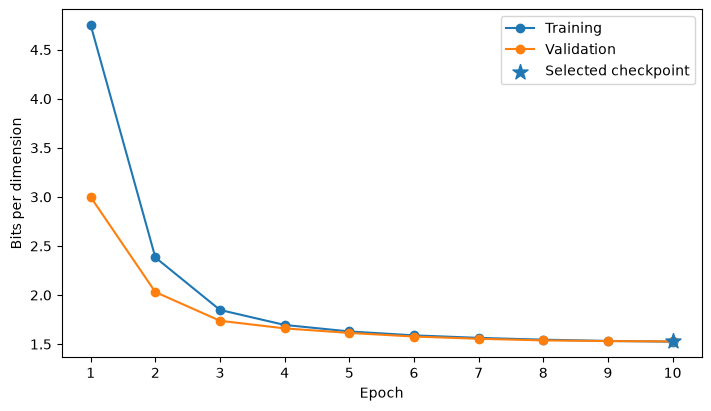

2536

In [35]:
reference_run = read_mnist_run('reference')
reference_config = reference_run['config']
mnist_reference_model = MNISTRealNVP(
    hidden_channels=reference_config['hidden_channels'], residual_blocks=reference_config['residual_blocks'],
).to(DEVICE)
mnist_reference_model.load_state_dict(reference_run['model_state'])
mnist_reference_model.eval()
_, _, mnist_test_loader = make_mnist_loaders(batch_size=reference_config['batch_size'])
test_bpd = evaluate_mnist_bpd(mnist_reference_model, mnist_test_loader, seed=MNIST_TEST_NOISE_SEED)

print(f"Best validation BPD {reference_run['best_val_bpd']:.4f} at epoch {reference_run['best_epoch']}")
print(f'Test BPD {test_bpd:.4f} on {len(mnist_test_loader.dataset):,} images')

history = reference_run['history']
epochs = [row['epoch'] for row in history]
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.plot(epochs, [row['train_bpd'] for row in history], 'o-', label='Training')
ax.plot(epochs, [row['val_bpd'] for row in history], 'o-', label='Validation')
ax.scatter(reference_run['best_epoch'], reference_run['best_val_bpd'], marker='*', s=130,
           label='Selected checkpoint', zorder=3)
ax.set(xlabel='Epoch', ylabel='Bits per dimension', xticks=epochs)
ax.legend()
fig.savefig(MNIST_RESULTS / 'learning_curves.png', dpi=180)
plt.show()

reference_metrics = {key: reference_run[key] for key in ('config', 'history', 'best_epoch', 'best_val_bpd')}
reference_metrics.update(test_bpd=test_bpd, test_noise_seed=MNIST_TEST_NOISE_SEED)
(MNIST_RESULTS / 'metrics.json').write_text(json.dumps(reference_metrics, indent=2) + '\n', encoding='utf-8')

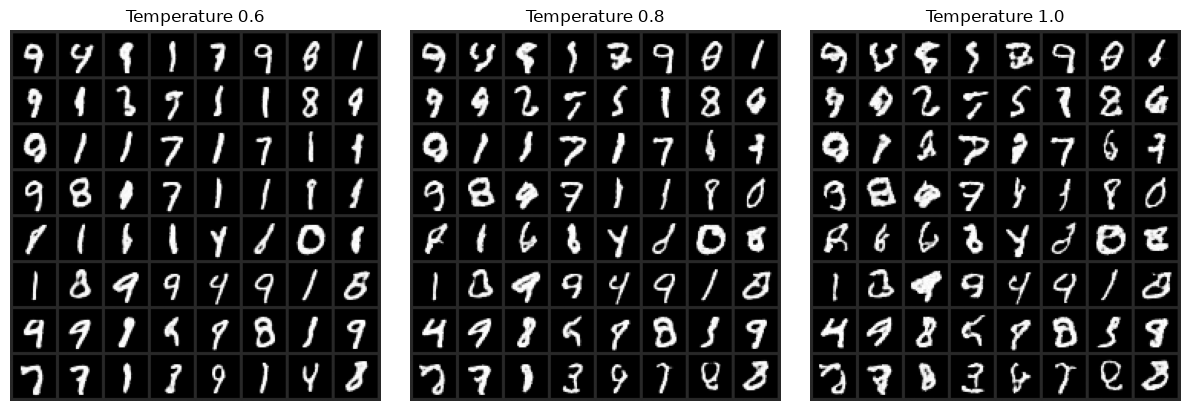

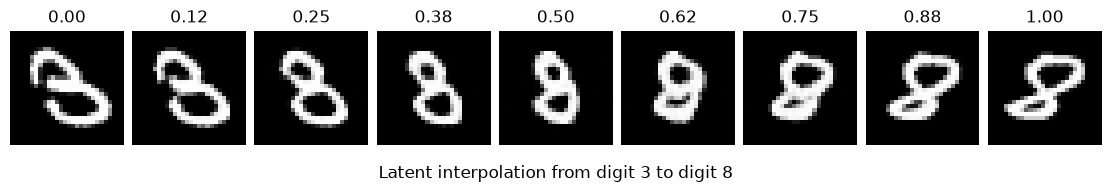

Test indices for digits (3, 8): (18, 61)


In [36]:
@torch.inference_mode()
def decode_mnist_images(model, z):
    logits, _ = model.inverse(z)
    return mnist_from_logits(logits).clamp(0, 1).cpu()


sample_generator = torch.Generator(device=DEVICE).manual_seed(SEED + 3)
z = torch.randn(64, mnist_reference_model.num_pixels, device=DEVICE, generator=sample_generator)
temperatures = (0.6, 0.8, 1.0)
fig, axes = plt.subplots(1, len(temperatures), figsize=(12, 4), layout='constrained')
for ax, temperature in zip(axes, temperatures):
    samples = decode_mnist_images(mnist_reference_model, z * temperature)
    grid = make_grid(samples, nrow=8, padding=2, pad_value=0.16)
    ax.imshow(grid[0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Temperature {temperature:.1f}')
    ax.axis('off')
fig.savefig(MNIST_RESULTS / 'temperature_samples.png', dpi=180)
plt.show()

# Choose fixed test endpoints for a repeatable interpolation.
test_images, test_labels = mnist_test_set.tensors
digits = (3, 8)
endpoint_indices = [torch.where(test_labels == digit)[0][0].item() for digit in digits]
interp_generator = torch.Generator(device=DEVICE).manual_seed(SEED + 4)
with torch.inference_mode():
    endpoints = dequantize_mnist(test_images[endpoint_indices].to(DEVICE), generator=interp_generator)
    endpoint_logits, _ = mnist_to_logits(endpoints)
    endpoint_z, _ = mnist_reference_model(endpoint_logits)
    weights = torch.linspace(0, 1, 9, device=DEVICE)
    interpolation_latents = torch.lerp(endpoint_z[0], endpoint_z[1], weights[:, None])
    interpolations = decode_mnist_images(mnist_reference_model, interpolation_latents)

fig, axes = plt.subplots(1, len(weights), figsize=(11, 1.8), layout='constrained')
for ax, image, weight in zip(axes, interpolations, weights.cpu().tolist()):
    ax.imshow(image[0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{weight:.2f}')
    ax.axis('off')
fig.supxlabel(f'Latent interpolation from digit {digits[0]} to digit {digits[1]}')
fig.savefig(MNIST_RESULTS / 'latent_interpolation.png', dpi=180)
plt.show()
print(f'Test indices for digits {digits}: {tuple(endpoint_indices)}')

### Temperature, interpolation and a learning-rate ablation

The temperature panels reuse the same 64 latent draws so you can compare each image across temperatures. Scaling $z$ by $T$ changes the prior from $\mathcal{N}(0, I)$ to $\mathcal{N}(0,T^2 I)$, so only $T=1$ samples the fitted model's prior. In your report, describe any quality or diversity differences and whether the interpolation through digit space looks gradual.

The ablation compares peak learning rates of $5\times 10^{-4}$ and $5\times 10^{-5}$ over two fresh 3-epoch runs. Both use the same seed, batch sequence, model configuration and warm-up and decay shape. The short reference has its own cosine schedule ending in epoch 3. Compare their validation curves, including how quickly each run improves and where they finish.

In [37]:
# TRAINING 2 OF 3 | Run this cell manually for the short reference.
fit_mnist_flow('ablation_reference', epochs=MNIST_ABLATION_EPOCHS, peak_lr=MNIST_PEAK_LR)

ablation_reference | epoch 01/3 | train 4.7493 BPD | val 2.9776 BPD | skipped 0 | 112.8 s
ablation_reference | epoch 02/3 | train 2.3781 BPD | val 2.0050 BPD | skipped 0 | 120.6 s
ablation_reference | epoch 03/3 | train 1.8955 BPD | val 1.8512 BPD | skipped 0 | 123.5 s
Best validation BPD 1.8512 at epoch 3.


In [38]:
# TRAINING 3 OF 3 | Run this cell manually for the low learning rate.
fit_mnist_flow('ablation_low_lr', epochs=MNIST_ABLATION_EPOCHS, peak_lr=MNIST_LOW_LR)

ablation_low_lr | epoch 01/3 | train 6.5322 BPD | val 5.5603 BPD | skipped 0 | 132.0 s
ablation_low_lr | epoch 02/3 | train 4.3682 BPD | val 3.7887 BPD | skipped 0 | 104.4 s
ablation_low_lr | epoch 03/3 | train 3.6549 BPD | val 3.6071 BPD | skipped 0 | 101.7 s
Best validation BPD 3.6071 at epoch 3.


Peak LR 5e-04 | epoch 3 validation 1.8512 BPD | best 1.8512 at epoch 3
Peak LR 5e-05 | epoch 3 validation 3.6071 BPD | best 3.6071 at epoch 3


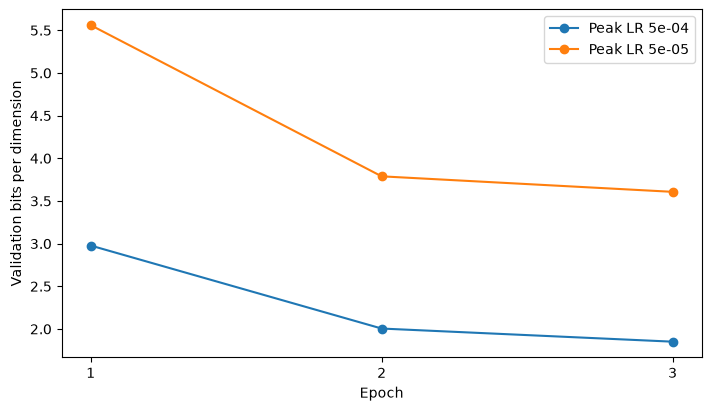

Final validation BPD difference (low LR minus reference) +1.7559


2285

In [39]:
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ablation_metrics = {}
for run_name in ('ablation_reference', 'ablation_low_lr'):
    record = read_mnist_run(run_name)
    peak_lr = record['config']['peak_lr']
    epochs = [row['epoch'] for row in record['history']]
    values = [row['val_bpd'] for row in record['history']]
    ax.plot(epochs, values, 'o-', label=f'Peak LR {peak_lr:.0e}')
    print(f'Peak LR {peak_lr:.0e} | epoch {epochs[-1]} validation {values[-1]:.4f} BPD | '
          f"best {record['best_val_bpd']:.4f} at epoch {record['best_epoch']}")
    ablation_metrics[run_name] = {key: record[key] for key in ('config', 'history', 'best_epoch', 'best_val_bpd')}

ax.set(xlabel='Epoch', ylabel='Validation bits per dimension', xticks=epochs)
ax.legend()
fig.savefig(MNIST_RESULTS / 'learning_rate_ablation.png', dpi=180)
plt.show()

last_bpd = {name: entry['history'][-1]['val_bpd'] for name, entry in ablation_metrics.items()}
final_difference = last_bpd['ablation_low_lr'] - last_bpd['ablation_reference']
print(f'Final validation BPD difference (low LR minus reference) {final_difference:+.4f}')
(MNIST_RESULTS / 'ablation_metrics.json').write_text(json.dumps(ablation_metrics, indent=2) + '\n', encoding='utf-8')

## Round 6 | Standard GAN on Fashion-MNIST

Run the notebook setup first. This section implements the first two practical parts of Question 2 in [Homework 2](DGM_HW2.pdf), using the [Fashion-MNIST training split](https://github.com/zalandoresearch/fashion-mnist). The images stay grayscale and `28 x 28`. The loader keeps raw pixels in memory and maps each minibatch into `[-1, 1]` before the discriminator sees it.

Both runs use five epochs, batch size 128, Adam with learning rate `2e-4` and betas `(0.5, 0.999)`, and one discriminator update per generator update. The seed fixes initialization, minibatch order and training noise for the two runs. A separate set of 64 latent vectors stays fixed across epochs and is shared with WGAN-GP in the next round.

In [40]:
from pathlib import Path

from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST


class FashionMNISTDataset(FashionMNIST):
    # The official repository also serves the archives over HTTPS.
    mirrors = [
        'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/',
        *FashionMNIST.mirrors,
    ]


FASHION_ROOT = Path('data')
FASHION_BATCH_SIZE = 128
FASHION_EPOCHS = 5
GAN_LATENT_DIM = 100
GAN_FIXED_NOISE_SEED = SEED + 100
GAN_TRAIN_NOISE_SEED = SEED + 101
FASHION_RESULTS = Path('results/fashion_gan')

fashion_data = FashionMNISTDataset(FASHION_ROOT, train=True, download=True)
fashion_train_set = TensorDataset(fashion_data.data.unsqueeze(1), fashion_data.targets)
GAN_FIXED_NOISE = torch.randn(64, GAN_LATENT_DIM, generator=torch.Generator().manual_seed(GAN_FIXED_NOISE_SEED))


def make_fashion_loader(*, batch_size=FASHION_BATCH_SIZE, seed=SEED):
    return DataLoader(
        fashion_train_set, batch_size=batch_size, shuffle=True, num_workers=0,
        pin_memory=DEVICE.type == 'cuda', generator=torch.Generator().manual_seed(seed),
    )


def fashion_to_gan_range(pixels):
    return pixels.to(dtype=torch.float32) / 127.5 - 1.0


print(f'Fashion-MNIST | {len(fashion_train_set):,} training images | shape {tuple(fashion_train_set[0][0].shape)}')

Fashion-MNIST | 60,000 training images | shape (1, 28, 28)


In [41]:
class FashionGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(GAN_LATENT_DIM, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 1024), nn.ReLU(),
            nn.Linear(1024, 28 * 28), nn.Tanh(),
        )

    def forward(self, z):
        return self.network(z).unflatten(1, (1, 28, 28))


class FashionImageScorer(nn.Module):
    """Produce a raw logit for a GAN or a raw score for WGAN-GP."""

    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(28 * 28, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
        )

    def forward(self, images):
        return self.network(images).squeeze(1)


def make_fashion_models():
    with torch.random.fork_rng(devices=[]):
        torch.random.default_generator.manual_seed(SEED)
        generator, scorer = FashionGenerator(), FashionImageScorer()
    return generator.to(DEVICE), scorer.to(DEVICE)

### Generator losses and confident rejection

The discriminator uses BCE with logits for the real and fake targets. For the generator, let $a$ be the fake logit and $p=\sigma(a)$. We minimize $-\log p$ in the non-saturating run and $\log(1-p)$ in the saturating run. Both are computed from logits. A negative saturating loss is expected.

| Fake probability $p$ | Non-saturating $\lvert\partial L/\partial a\rvert=1-p$ | Saturating $\lvert\partial L/\partial a\rvert=p$ |
| --- | ---: | ---: |
| 0.01 | 0.99 | 0.01 |
| 0.50 | 0.50 | 0.50 |

These coefficients multiply the gradient through the fake logit. The training logs track the fraction of fake images assigned $p\leq0.01$ during the generator update so you can connect the loss curves and images to actual periods of confident rejection.

In [42]:
import json
from tempfile import NamedTemporaryFile
from time import perf_counter

import matplotlib.pyplot as plt
from torchvision.utils import save_image

GAN_BCE = nn.BCEWithLogitsLoss()
GAN_OBJECTIVES = ('non_saturating', 'saturating')
GAN_LEARNING_RATE = 2e-4
GAN_ADAM_BETAS = (0.5, 0.999)
GAN_CONFIDENCE_THRESHOLD = 0.01


def gan_generator_loss(fake_logits, objective):
    if objective == 'non_saturating':
        return GAN_BCE(fake_logits, torch.ones_like(fake_logits))
    if objective == 'saturating':
        return -GAN_BCE(fake_logits, torch.zeros_like(fake_logits))
    raise ValueError(f'Unknown generator objective: {objective}')


@torch.inference_mode()
def save_fashion_grid(generator, directory, epoch):
    images = generator(GAN_FIXED_NOISE.to(DEVICE)).cpu()
    images = ((images + 1.0) / 2.0).clamp(0, 1)
    directory.mkdir(parents=True, exist_ok=True)
    save_image(images, directory / f'epoch_{epoch:02d}.png', nrow=8, padding=2, pad_value=0.16)


def write_fashion_metrics(directory, record):
    directory.mkdir(parents=True, exist_ok=True)
    with NamedTemporaryFile(dir=directory, suffix='.tmp', delete=False) as handle:
        pending = Path(handle.name)
    try:
        pending.write_text(json.dumps(record, indent=2, allow_nan=False) + '\n', encoding='utf-8')
        pending.replace(directory / 'metrics.json')
    finally:
        pending.unlink(missing_ok=True)


def read_fashion_metrics(run_name):
    path = FASHION_RESULTS / run_name / 'metrics.json'
    if not path.is_file():
        raise FileNotFoundError(f'Run the training cell for {run_name!r} first. Missing {path}.')
    record = json.loads(path.read_text(encoding='utf-8'))
    if len(record['history']) != record['config']['epochs']:
        raise RuntimeError(f'{run_name!r} ended before its last epoch.')
    return record


def plot_fashion_grids(runs, filename):
    """Lay out each run's fixed-noise grids in epoch order."""
    records = {name: read_fashion_metrics(name) for name in runs}
    epoch_count = max(len(record['history']) for record in records.values())
    fig, axes = plt.subplots(len(runs), epoch_count, figsize=(2.6 * epoch_count, 2.8 * len(runs)),
                             squeeze=False, layout='constrained')
    for row, (name, label) in zip(axes, runs.items()):
        for ax in row:
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
        row[0].set_ylabel(label, labelpad=6)
        for ax, stats in zip(row, records[name]['history']):
            epoch = stats['epoch']
            image = plt.imread(FASHION_RESULTS / name / f'epoch_{epoch:02d}.png')
            ax.imshow(image)
            ax.set_title(f'Epoch {epoch}')
    fig.savefig(FASHION_RESULTS / filename, dpi=180)
    plt.show()

In [43]:
@torch.inference_mode()
def check_fashion_models():
    generator, discriminator = make_fashion_models()
    raw_images, _ = next(iter(make_fashion_loader(batch_size=8)))
    real = fashion_to_gan_range(raw_images.to(DEVICE))
    fake = generator(GAN_FIXED_NOISE[:8].to(DEVICE))
    assert real.shape == fake.shape == (8, 1, 28, 28)
    assert discriminator(real).shape == discriminator(fake).shape == (8,)
    assert (real.abs() <= 1).all() and (fake.abs() <= 1).all()
    endpoints = torch.tensor([0, 255], dtype=torch.uint8)
    torch.testing.assert_close(fashion_to_gan_range(endpoints), torch.tensor([-1.0, 1.0]))


check_fashion_models()
probabilities = torch.tensor([0.01, 0.5], dtype=torch.float64)
example_logits = torch.logit(probabilities).requires_grad_()
for objective, expected in (
    ('non_saturating', 1 - probabilities), ('saturating', probabilities),
):
    # Multiply by the count to undo the reduction over the two independent logits.
    loss = gan_generator_loss(example_logits, objective) * len(probabilities)
    slope, = torch.autograd.grad(loss, example_logits)
    torch.testing.assert_close(slope, -expected)
    print(f'{objective}: gradient magnitudes {slope.abs().tolist()}')
print('Fashion-MNIST shapes, pixel range and both generator loss derivatives passed.')

non_saturating: gradient magnitudes [0.99, 0.5]
saturating: gradient magnitudes [0.010000000000000002, 0.5]
Fashion-MNIST shapes, pixel range and both generator loss derivatives passed.


In [44]:
def fit_standard_gan(objective, *, epochs=FASHION_EPOCHS, batch_size=FASHION_BATCH_SIZE):
    if objective not in GAN_OBJECTIVES:
        raise ValueError(f'Unknown generator objective: {objective}')
    loader = make_fashion_loader(batch_size=batch_size)
    generator, discriminator = make_fashion_models()
    optimizer_options = dict(lr=GAN_LEARNING_RATE, betas=GAN_ADAM_BETAS, eps=1e-8, weight_decay=0)
    g_optimizer = torch.optim.Adam(generator.parameters(), **optimizer_options)
    d_optimizer = torch.optim.Adam(discriminator.parameters(), **optimizer_options)
    train_noise = torch.Generator(device=DEVICE).manual_seed(GAN_TRAIN_NOISE_SEED)
    directory = FASHION_RESULTS / objective
    columns = (
        'd_loss', 'g_loss', 'p_real', 'p_fake', 'p_fake_for_g', 'confident_rejection_fraction',
    )
    record = {
        'objective': objective,
        'config': {
            'epochs': epochs, 'batch_size': batch_size, 'batches_per_epoch': len(loader),
            'optimizer': 'Adam', **optimizer_options, 'latent_dim': GAN_LATENT_DIM,
            'seed': SEED, 'fixed_noise_seed': GAN_FIXED_NOISE_SEED, 'train_noise_seed': GAN_TRAIN_NOISE_SEED,
            'confidence_threshold': GAN_CONFIDENCE_THRESHOLD,
        },
        'history': [],
        'batches': {'columns': ['batch_size', *columns], 'rows': []},
    }

    for epoch in range(1, epochs + 1):
        started = perf_counter()
        generator.train()
        discriminator.train()
        batch_values = torch.empty(len(loader), len(columns), device=DEVICE)
        batch_sizes = []
        for batch_index, (pixels, _) in enumerate(loader):
            real = fashion_to_gan_range(pixels.to(DEVICE, non_blocking=DEVICE.type == 'cuda'))
            z = torch.randn(len(real), GAN_LATENT_DIM, device=DEVICE, generator=train_noise)
            fake = generator(z)

            d_optimizer.zero_grad(set_to_none=True)
            real_logits = discriminator(real)
            fake_logits = discriminator(fake.detach())
            d_loss = GAN_BCE(real_logits, torch.ones_like(real_logits)) + GAN_BCE(fake_logits, torch.zeros_like(fake_logits))
            d_loss.backward()
            d_optimizer.step()

            g_optimizer.zero_grad(set_to_none=True)
            discriminator.requires_grad_(False)
            update_logits = discriminator(fake)
            g_loss = gan_generator_loss(update_logits, objective)
            g_loss.backward()
            g_optimizer.step()
            discriminator.requires_grad_(True)

            # Record D's two probabilities before its update and the probability used by G after it.
            update_probability = update_logits.detach().sigmoid()
            batch_values[batch_index] = torch.stack((
                d_loss.detach(), g_loss.detach(), real_logits.detach().sigmoid().mean(),
                fake_logits.detach().sigmoid().mean(), update_probability.mean(),
                (update_probability <= GAN_CONFIDENCE_THRESHOLD).float().mean(),
            ))
            batch_sizes.append(len(real))

        values = batch_values.cpu()
        if not torch.isfinite(values).all():
            raise FloatingPointError(f'{objective}: nonfinite metrics in epoch {epoch}.')
        sizes = torch.tensor(batch_sizes, dtype=values.dtype)
        means = (sizes @ values / sizes.sum()).tolist()
        stats = dict(zip(columns, means))
        stats.update(epoch=epoch, seconds=perf_counter() - started)
        generator.eval()
        save_fashion_grid(generator, directory, epoch)
        record['history'].append(stats)
        record['batches']['rows'].extend(torch.cat((sizes[:, None], values), dim=1).tolist())
        write_fashion_metrics(directory, record)
        print(f"{objective} | epoch {epoch:02d}/{epochs} | D {stats['d_loss']:.4f} | G {stats['g_loss']:.4f} | "
              f"p(real) {stats['p_real']:.3f} | p(fake) {stats['p_fake']:.3f} | {stats['seconds']:.1f} s", flush=True)

In [45]:
# TRAINING 1 OF 2 | Run this cell manually for the standard GAN.
fit_standard_gan('non_saturating')

non_saturating | epoch 01/5 | D 0.6343 | G 2.2623 | p(real) 0.879 | p(fake) 0.345 | 3.8 s
non_saturating | epoch 02/5 | D 0.6273 | G 3.3540 | p(real) 0.839 | p(fake) 0.219 | 3.7 s
non_saturating | epoch 03/5 | D 0.5191 | G 3.6090 | p(real) 0.868 | p(fake) 0.168 | 3.6 s
non_saturating | epoch 04/5 | D 0.4706 | G 3.7035 | p(real) 0.875 | p(fake) 0.149 | 3.6 s
non_saturating | epoch 05/5 | D 0.5859 | G 3.1698 | p(real) 0.827 | p(fake) 0.189 | 3.5 s


In [46]:
# TRAINING 2 OF 2 | Run this cell manually for the saturating variant.
fit_standard_gan('saturating')

saturating | epoch 01/5 | D 0.4769 | G -0.2283 | p(real) 0.918 | p(fake) 0.262 | 3.8 s
saturating | epoch 02/5 | D 0.5390 | G -0.0440 | p(real) 0.873 | p(fake) 0.177 | 3.8 s
saturating | epoch 03/5 | D 0.4793 | G -0.0477 | p(real) 0.880 | p(fake) 0.156 | 3.7 s
saturating | epoch 04/5 | D 0.4420 | G -0.0386 | p(real) 0.883 | p(fake) 0.148 | 3.6 s
saturating | epoch 05/5 | D 0.6357 | G -0.1149 | p(real) 0.855 | p(fake) 0.167 | 3.5 s


### Compare the two standard GAN runs

Run this after both fits. Each epoch point is weighted by the number of images in each batch. `p(fake) for G` comes from the updated discriminator and is the probability that determines the generator's logit gradient multiplier. Compare the samples at the same epoch and position, and use the confident-rejection summary to find epochs worth discussing.

Non-saturating | highest epoch share of G samples with p(fake) <= 0.01: 13.28% at epoch 4
Saturating | highest epoch share of G samples with p(fake) <= 0.01: 21.03% at epoch 5


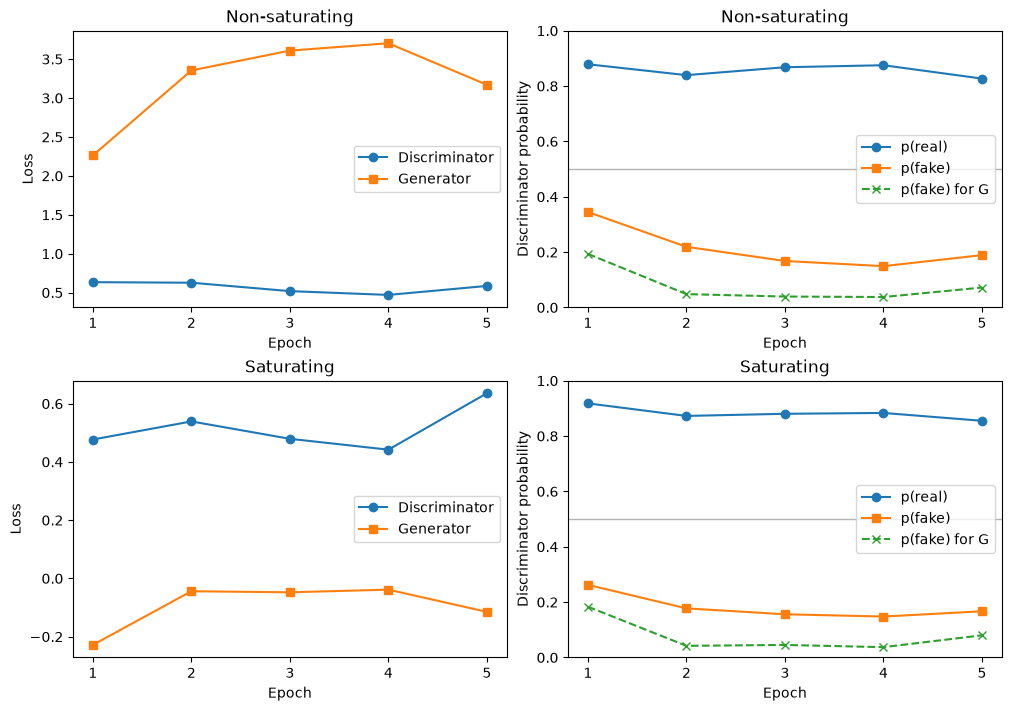

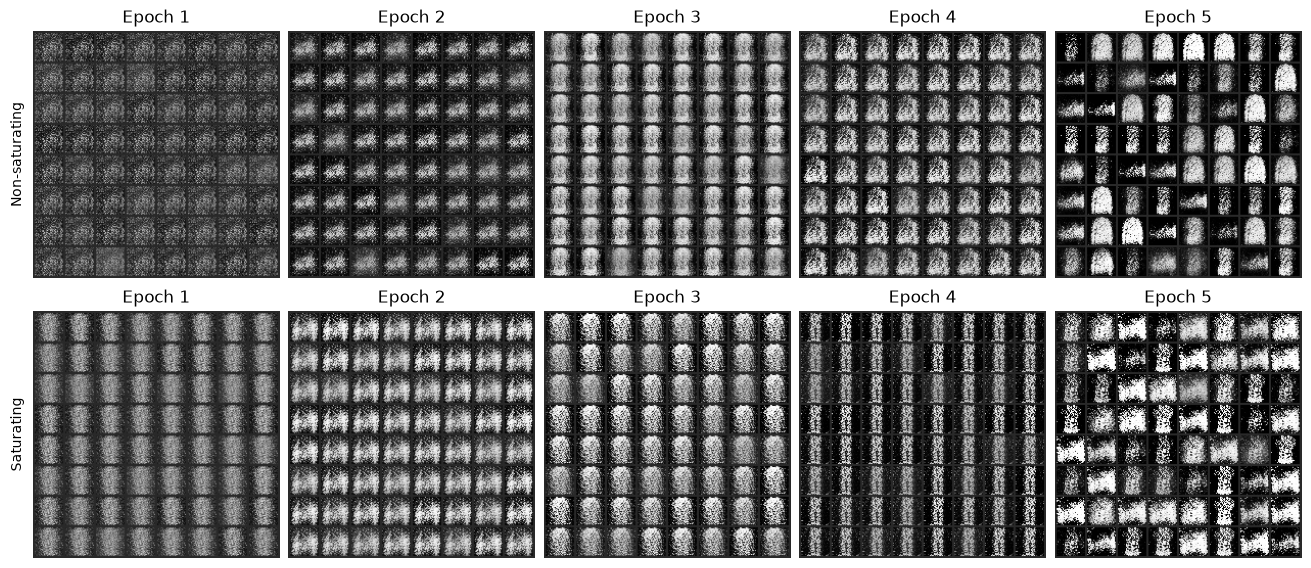

In [47]:
standard_gan_runs = {'non_saturating': 'Non-saturating', 'saturating': 'Saturating'}
fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout='constrained')
for (name, label), (loss_ax, prob_ax) in zip(standard_gan_runs.items(), axes):
    history = read_fashion_metrics(name)['history']
    epochs = [row['epoch'] for row in history]
    loss_ax.plot(epochs, [row['d_loss'] for row in history], 'o-', label='Discriminator')
    loss_ax.plot(epochs, [row['g_loss'] for row in history], 's-', label='Generator')
    loss_ax.set(title=label, xlabel='Epoch', ylabel='Loss', xticks=epochs)
    loss_ax.legend()
    prob_ax.plot(epochs, [row['p_real'] for row in history], 'o-', label='p(real)')
    prob_ax.plot(epochs, [row['p_fake'] for row in history], 's-', label='p(fake)')
    prob_ax.plot(epochs, [row['p_fake_for_g'] for row in history], 'x--', label='p(fake) for G')
    prob_ax.axhline(0.5, color='0.7', linewidth=1)
    prob_ax.set(title=label, xlabel='Epoch', ylabel='Discriminator probability', xticks=epochs, ylim=(0, 1))
    prob_ax.legend()
    hardest_epoch = max(history, key=lambda row: row['confident_rejection_fraction'])
    fraction = hardest_epoch['confident_rejection_fraction']
    print(f"{label} | highest epoch share of G samples with p(fake) <= {GAN_CONFIDENCE_THRESHOLD:g}: "
          f"{fraction:.2%} at epoch {hardest_epoch['epoch']}")

fig.savefig(FASHION_RESULTS / 'standard_gan_curves.png', dpi=180)
plt.show()
plot_fashion_grids(standard_gan_runs, 'standard_gan_samples.png')

## Round 7 | WGAN-GP and three-way comparison

Run the notebook setup and the Round 6 data, model and output definitions first. This round uses the same Fashion-MNIST loader, generator, raw image scorer and fixed noise. Train for five epochs with batch size 128. The raw scorer is now a critic with unbounded outputs. The objectives below follow [Gulrajani et al., section 4 and Algorithm 1](papers/NIPS-2017-improved-training-of-wasserstein-gans-Paper.pdf), using the three critic updates per generator update specified by [Homework 2](DGM_HW2.pdf).

For each fake and real pair, draw one scalar uniformly and interpolate between the two images. The critic minimizes $\operatorname{mean} C(x_{\mathrm{fake}})-\operatorname{mean} C(x_{\mathrm{real}})+10\,\mathrm{GP}$, where $\mathrm{GP}=\operatorname{mean}(\lVert\nabla_{\hat{x}}C(\hat{x})\rVert_2-1)^2$ averages over interpolated images. The generator minimizes $-\operatorname{mean} C(G(z))$. The critic gap is the real mean score minus the fake mean score, before adding the penalty.

In [48]:
WGAN_RUN = 'wgan_gp'
WGAN_LEARNING_RATE = 1e-4
WGAN_ADAM_BETAS = (0.0, 0.9)
WGAN_CRITIC_STEPS = 3
WGAN_GP_WEIGHT = 10.0
WGAN_INTERPOLATION_SEED = SEED + 102


def wgan_gradient_penalty(critic, real, fake, *, generator):
    """Return the mean squared deviation of each input-gradient norm from one."""
    mixes = torch.rand(len(real), 1, 1, 1, dtype=real.dtype, device=real.device, generator=generator)
    interpolated = torch.lerp(fake.detach(), real.detach(), mixes).requires_grad_(True)
    input_gradient, = torch.autograd.grad(critic(interpolated).sum(), interpolated, create_graph=True)
    gradient_norms = input_gradient.flatten(start_dim=1).norm(p=2, dim=1)
    return (gradient_norms - 1.0).square().mean()

In [49]:
# A linear critic C(x) = scale * x[0, 0, 0] has input-gradient norm |scale|.
real_example = torch.ones(4, 1, 28, 28, device=DEVICE)
fake_example = torch.zeros_like(real_example)
example_rng = torch.Generator(device=DEVICE).manual_seed(WGAN_INTERPOLATION_SEED)
for magnitude in (1.0, 2.0):
    scale = torch.tensor(magnitude, device=DEVICE, requires_grad=True)
    penalty = wgan_gradient_penalty(
        lambda images: scale * images[:, 0, 0, 0], real_example, fake_example, generator=example_rng,
    )
    scale_gradient, = torch.autograd.grad(penalty, scale)
    torch.testing.assert_close(penalty, scale.new_tensor((magnitude - 1.0)**2))
    torch.testing.assert_close(scale_gradient, scale.new_tensor(2.0 * (magnitude - 1.0)))
    print(f'Gradient norm {magnitude:.0f} | penalty {penalty.item():.0f} | derivative {scale_gradient.item():.0f}')

Gradient norm 1 | penalty 0 | derivative 0
Gradient norm 2 | penalty 1 | derivative 2


In [50]:
from math import isfinite


def fit_fashion_wgan_gp(*, epochs=FASHION_EPOCHS, batch_size=FASHION_BATCH_SIZE):
    loader = make_fashion_loader(batch_size=batch_size)
    if len(loader) < WGAN_CRITIC_STEPS:
        raise ValueError('WGAN-GP needs at least three minibatches per epoch.')
    generator, critic = make_fashion_models()
    optimizer_options = dict(lr=WGAN_LEARNING_RATE, betas=WGAN_ADAM_BETAS, eps=1e-8, weight_decay=0)
    g_optimizer = torch.optim.Adam(generator.parameters(), **optimizer_options)
    c_optimizer = torch.optim.Adam(critic.parameters(), **optimizer_options)
    train_noise = torch.Generator(device=DEVICE).manual_seed(GAN_TRAIN_NOISE_SEED)
    interpolation_noise = torch.Generator(device=DEVICE).manual_seed(WGAN_INTERPOLATION_SEED)
    directory = FASHION_RESULTS / WGAN_RUN
    record = {
        'objective': WGAN_RUN,
        'config': {
            'epochs': epochs, 'batch_size': batch_size, 'batches_per_epoch': len(loader),
            'optimizer': 'Adam', **optimizer_options, 'latent_dim': GAN_LATENT_DIM,
            'critic_steps_per_generator_step': WGAN_CRITIC_STEPS, 'gp_weight': WGAN_GP_WEIGHT,
            'seed': SEED, 'fixed_noise_seed': GAN_FIXED_NOISE_SEED, 'train_noise_seed': GAN_TRAIN_NOISE_SEED,
            'interpolation_seed': WGAN_INTERPOLATION_SEED,
        },
        'history': [],
    }
    critic_columns = ('critic_loss', 'critic_gap', 'gradient_penalty')
    critic_updates = 0

    def draw_latents(count):
        return torch.randn(count, GAN_LATENT_DIM, device=DEVICE, generator=train_noise)

    for epoch in range(1, epochs + 1):
        started = perf_counter()
        generator.train()
        critic.train()
        critic_totals = torch.zeros(len(critic_columns), device=DEVICE, dtype=torch.float64)
        generator_total = torch.zeros((), device=DEVICE, dtype=torch.float64)
        critic_images = generator_images = generator_updates = 0
        for pixels, _ in loader:
            real = fashion_to_gan_range(pixels.to(DEVICE, non_blocking=DEVICE.type == 'cuda'))
            count = len(real)
            with torch.no_grad():
                fake = generator(draw_latents(count))

            c_optimizer.zero_grad(set_to_none=True)
            gap = critic(real).mean() - critic(fake).mean()
            penalty = wgan_gradient_penalty(critic, real, fake, generator=interpolation_noise)
            c_loss = -gap + WGAN_GP_WEIGHT * penalty
            c_loss.backward()
            c_optimizer.step()
            critic_totals += torch.stack((c_loss.detach(), gap.detach(), penalty.detach())) * count
            critic_images += count
            critic_updates += 1

            if critic_updates % WGAN_CRITIC_STEPS == 0:
                g_optimizer.zero_grad(set_to_none=True)
                critic.requires_grad_(False)
                g_loss = -critic(generator(draw_latents(count))).mean()
                g_loss.backward()
                g_optimizer.step()
                critic.requires_grad_(True)
                generator_total += g_loss.detach() * count
                generator_images += count
                generator_updates += 1

        stats = dict(zip(critic_columns, (critic_totals / critic_images).tolist()))
        stats['generator_loss'] = generator_total.item() / generator_images
        if not all(isfinite(value) for value in stats.values()):
            raise FloatingPointError(f'WGAN-GP produced nonfinite metrics in epoch {epoch}.')
        stats.update(epoch=epoch, critic_updates=len(loader), generator_updates=generator_updates,
                     seconds=perf_counter() - started)
        generator.eval()
        save_fashion_grid(generator, directory, epoch)
        record['history'].append(stats)
        write_fashion_metrics(directory, record)
        print(f"WGAN-GP | epoch {epoch:02d}/{epochs} | G {stats['generator_loss']:.4f} | "
              f"gap {stats['critic_gap']:.4f} | GP {stats['gradient_penalty']:.4f} | "
              f"C/G updates {stats['critic_updates']}/{generator_updates} | {stats['seconds']:.1f} s", flush=True)

In [51]:
# TRAINING | Run this cell manually to fit WGAN-GP.
fit_fashion_wgan_gp()

WGAN-GP | epoch 01/5 | G -2.1718 | gap 9.6648 | GP 0.1857 | C/G updates 469/156 | 4.0 s
WGAN-GP | epoch 02/5 | G -2.1713 | gap 11.7345 | GP 0.1971 | C/G updates 469/156 | 4.0 s
WGAN-GP | epoch 03/5 | G -1.2064 | gap 6.6999 | GP 0.0826 | C/G updates 469/157 | 4.0 s
WGAN-GP | epoch 04/5 | G 11.4731 | gap 10.5163 | GP 0.1486 | C/G updates 469/156 | 3.8 s
WGAN-GP | epoch 05/5 | G 17.4695 | gap 12.3846 | GP 0.1945 | C/G updates 469/156 | 3.7 s


### Evaluate WGAN-GP and compare all three runs

WGAN-GP uses Adam with learning rate `1e-4` and betas `(0.0, 0.9)`. All real minibatches are used. The critic update count carries across epoch boundaries, so generator updates occur after every third critic step even when a group spans two epochs. A final incomplete group contributes critic updates only. The plotted penalty is the unweighted mean squared deviation from unit input-gradient norm. Its contribution to the critic loss is ten times that value.

Compare the grid positions across epochs to judge how shapes, detail and variety change. For the BCE runs, real and fake probabilities show how strongly the discriminator separates the minibatches. For WGAN-GP, the critic gap measures separation in raw score units. Read the gap together with the gradient penalty and images. The gap tracks the current critic's scores, and the plotted critic loss also includes the penalty. BCE measures a different objective in different units, so the figures give them independent scales.

The penalty regularizes input gradients along sampled real-to-fake paths. This can help the critic provide usable generator gradients when the distributions are easy to separate. Use your runs to assess stability and visible variety. The penalty alone gives neither a global Lipschitz guarantee nor a guarantee of image quality or mode coverage.

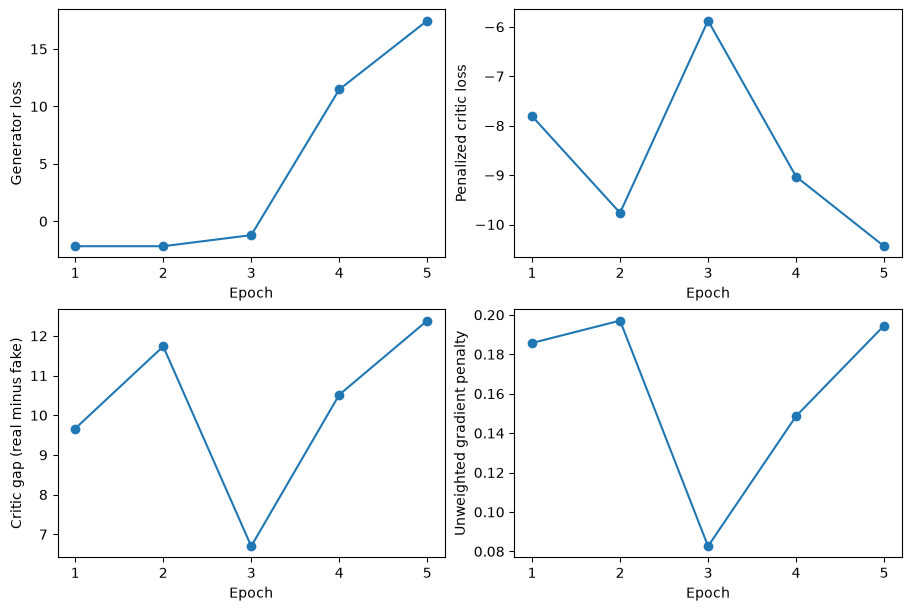

Final critic gap 12.3846 | gradient penalty 0.1945
Total updates | critic 2,345 | generator 781


In [52]:
wgan_history = read_fashion_metrics(WGAN_RUN)['history']
wgan_epochs = [row['epoch'] for row in wgan_history]
fig, axes = plt.subplots(2, 2, figsize=(9, 6), layout='constrained')
for ax, (key, label) in zip(axes.flat, (
    ('generator_loss', 'Generator loss'), ('critic_loss', 'Penalized critic loss'),
    ('critic_gap', 'Critic gap (real minus fake)'), ('gradient_penalty', 'Unweighted gradient penalty'),
)):
    ax.plot(wgan_epochs, [row[key] for row in wgan_history], 'o-')
    ax.set(xlabel='Epoch', ylabel=label, xticks=wgan_epochs)
fig.savefig(FASHION_RESULTS / 'wgan_gp_curves.png', dpi=180)
plt.show()

last = wgan_history[-1]
print(f"Final critic gap {last['critic_gap']:.4f} | gradient penalty {last['gradient_penalty']:.4f}")
print(f"Total updates | critic {sum(row['critic_updates'] for row in wgan_history):,} | "
      f"generator {sum(row['generator_updates'] for row in wgan_history):,}")

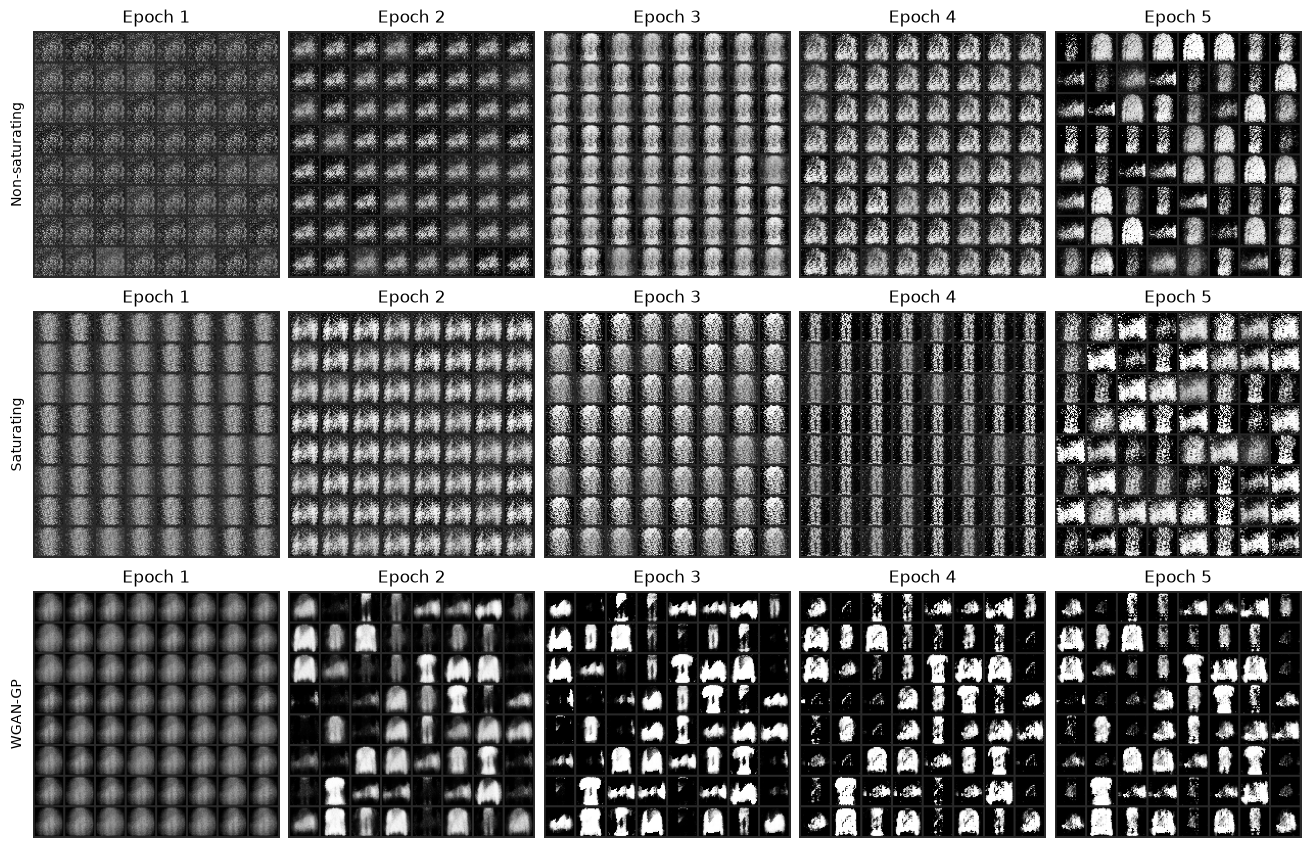

Non-saturating | epoch 4 | 13.28% of G samples had p(fake) <= 0.01
Saturating | epoch 5 | 21.03% of G samples had p(fake) <= 0.01


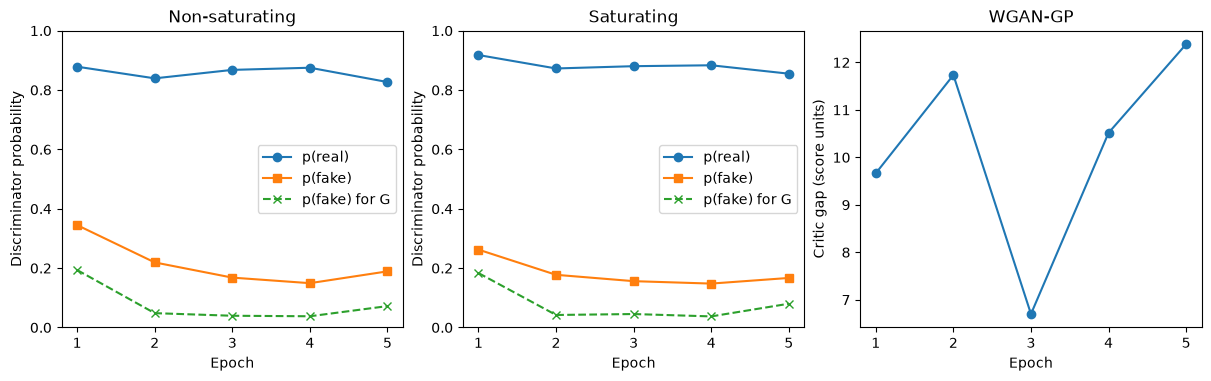

In [53]:
all_fashion_runs = {'non_saturating': 'Non-saturating', 'saturating': 'Saturating', WGAN_RUN: 'WGAN-GP'}
plot_fashion_grids(all_fashion_runs, 'fashion_three_way_samples.png')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), layout='constrained')
for ax, (name, label) in zip(axes, all_fashion_runs.items()):
    history = read_fashion_metrics(name)['history']
    epochs = [row['epoch'] for row in history]
    if name == WGAN_RUN:
        ax.plot(epochs, [row['critic_gap'] for row in history], 'o-')
        ax.set(ylabel='Critic gap (score units)')
    else:
        ax.plot(epochs, [row['p_real'] for row in history], 'o-', label='p(real)')
        ax.plot(epochs, [row['p_fake'] for row in history], 's-', label='p(fake)')
        ax.plot(epochs, [row['p_fake_for_g'] for row in history], 'x--', label='p(fake) for G')
        ax.set(ylabel='Discriminator probability', ylim=(0, 1))
        ax.legend()
        hardest = max(history, key=lambda row: row['confident_rejection_fraction'])
        print(f"{label} | epoch {hardest['epoch']} | "
              f"{hardest['confident_rejection_fraction']:.2%} of G samples had p(fake) <= 0.01")
    ax.set(title=label, xlabel='Epoch', xticks=epochs)
fig.savefig(FASHION_RESULTS / 'fashion_three_way_signals.png', dpi=180)
plt.show()